# L16 Optimization

These notes combine **Optimization (Introduction)** and **Optimization (ND Methods)**

Run code cells from top to bottom. Required packages: NumPy, SciPy, Matplotlib. All experiments use deterministic starting points.

In [1]:
%matplotlib inline
import numpy as np
import numpy.linalg as la
import scipy
import scipy.optimize as sopt
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from dataclasses import dataclass
plt.rcParams.update({'figure.figsize': (8, 4), 'figure.dpi': 110, 'axes.grid': True, 'font.size': 11})
print('NumPy', np.__version__, '| SciPy', scipy.__version__)

NumPy 2.5.4 | SciPy 1.18.1


# I Optimization: model, objective, and constraints

## 1. Optimization and Unconstrained Optimization

The minimizer is an input; the minimum value is a scalar output. The `argmin` is formally a set when there are multiple minimizers. In 1D the variable is a scalar $x$; in ND it is a vector $\mathbf x$ while $f(\mathbf x)$ remains scalar.

**Unconstrained Optimization** imposes no additional equality or inequality restrictions beyond the function's domain. For maximization, minimize the negative objective:
$$\operatorname*{arg\,max}f=\operatorname*{arg\,min}(-f),\qquad \max f=-\min(-f).$$

## 2. Constrained Optimization

The lecture writes the problem as
$$\min_{\mathbf x}f(\mathbf x)\quad\text{subject to}\quad h_i(\mathbf x)=0,\ i=1,\ldots,\ell,\qquad g_j(\mathbf x)\le0,\ j=1,\ldots,m.$$
Equality constraints restrict the point to a level set. Inequality constraints select one side of a boundary. A point satisfying all restrictions is **feasible**; the collection of feasible points is the **feasible region**.

The objective and constraints play different roles: a low objective value is irrelevant if the point is infeasible. A constrained optimum can lie on the boundary, where the unconstrained condition $\nabla f=0$ need not hold.

## 3. Calculus problem: maximize rectangle area subject to perimeter constraint

The design variables are $\mathbf x=(d_1,d_2)^T$. The instructor defines
$$A(\mathbf x)=d_1d_2,\qquad P(\mathbf x)=2(d_1+d_2).$$
Maximize $A$ subject to $P\le20$ and $d_1,d_2\ge0$. In the illustrated box $0\le d_i\le10$, ignoring the perimeter gives $(10,10)$ with area $100$ but perimeter $40$, which violates the constraint. The feasible set is the triangle $d_1+d_2\le10$ in the first quadrant. Area contours are hyperbolas; perimeter contours are straight lines.

<details>
<summary>Example: Rectangle optimum</summary>

Find the dimensions and maximum area of a rectangle with $P\le20$.

<details>
<summary>Solution</summary>

For nonnegative sides,
$$d_1d_2\le\left(\frac{d_1+d_2}{2}\right)^2\le25.$$
Equality requires $d_1=d_2$ and $d_1+d_2=10$. Thus $\boxed{\mathbf x^*=(5,5)^T,\ A^*=25,\ P^*=20}$. At the solution $\nabla A=(5,5)^T\ne0$: the active perimeter constraint prevents further feasible increase.

</details>
</details>

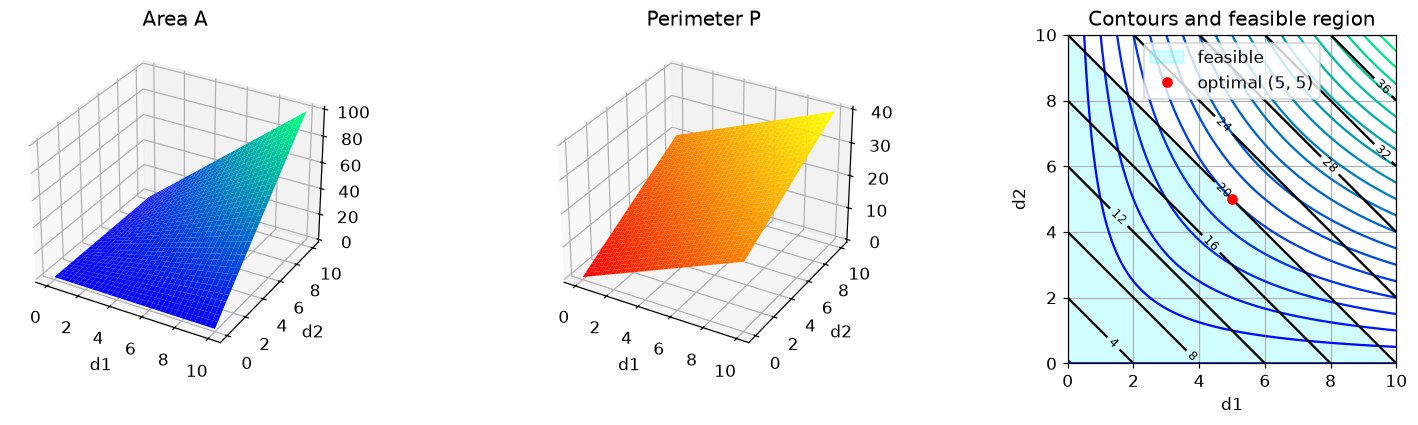

Dimensions: [5. 5.] | area: 25.000000000000107 | perimeter: 20.000000000000043


In [2]:
def A(x):
    return x[0] * x[1]

def P(x):
    return 2 * (x[0] + x[1])

xmesh, ymesh = np.mgrid[0:10:100j, 0:10:100j]
AMesh = A(np.array([xmesh, ymesh]))
PMesh = P(np.array([xmesh, ymesh]))
fig = plt.figure(figsize=(14, 4))
ax = fig.add_subplot(131, projection='3d')
ax.plot_surface(xmesh, ymesh, AMesh, cmap='winter', rstride=3, cstride=3)
ax.set(xlabel='d1', ylabel='d2', title='Area A')
ax = fig.add_subplot(132, projection='3d')
ax.plot_surface(xmesh, ymesh, PMesh, cmap='autumn', rstride=3, cstride=3)
ax.set(xlabel='d1', ylabel='d2', title='Perimeter P')
ax = fig.add_subplot(133)
ax.contour(xmesh, ymesh, AMesh, 20, cmap='winter')
pc = ax.contour(xmesh, ymesh, PMesh, 10, colors='black')
ax.clabel(pc, fontsize=8)
ax.fill([0, 10, 0], [0, 0, 10], alpha=.18, color='cyan', label='feasible')
ax.plot(5, 5, 'ro', label='optimal (5, 5)')
ax.set(xlabel='d1', ylabel='d2', aspect='equal', title='Contours and feasible region')
ax.legend(); fig.tight_layout(); plt.show()

rectangle = minimize(lambda x: -A(x), np.array([9., 1.]), method='SLSQP',
                     bounds=((0., 10.), (0., 10.)),
                     constraints=({'type': 'ineq', 'fun': lambda x: 20. - P(x)},),
                     options={'ftol': 1e-12, 'maxiter': 100})
assert rectangle.success and np.allclose(rectangle.x, [5., 5.], atol=1e-5)
assert P(rectangle.x) <= 20. + 1e-8
print('Dimensions:', rectangle.x, '| area:', A(rectangle.x), '| perimeter:', P(rectangle.x))

**Implementation convention:** SciPy's dictionary constraint `{'type': 'ineq', 'fun': g}` means $g(\mathbf x)\ge0$. Hence the code uses $20-P$, the negative of the lecture's $P-20\le0$. The explicit nonnegative bounds retain the physical meaning of side lengths. `fig.add_subplot(..., projection='3d')` replaces the instructor's obsolete `fig.gca(projection='3d')` call.

# II What is the optimal solution? (1D)

## 1. Existence, local solutions, and global solutions

A **global minimizer** satisfies $f(x^*)\le f(x)$ for every feasible $x$. A **local minimizer** only requires this inequality in some neighborhood of $x^*$. A strict local minimizer has strict inequality for nearby distinct points.

A minimizer need not exist: $f(x)=e^x$ on $\mathbb R$ has infimum $0$ but never attains it. A continuous function on a nonempty compact feasible set does attain its minimum. The rectangle problem meets this condition; the unconstrained domain $\mathbb R^n$ is not compact. Convexity, when available, makes every local minimizer global, but these methods are also applied to nonconvex functions.

## 2. First-order necessary and second-order sufficient conditions

Assume $x^*$ is an **interior** point of the domain.

**(First-order) Necessary condition:** if $f$ is differentiable and $x^*$ is a local minimizer or maximizer,
$$\boxed{f'(x^*)=0.}$$
Such a point is a **stationary point**. Necessity does not imply sufficiency: $x^3$ is stationary at zero but has no extremum there.

**(Second-order) Sufficient condition:** for $f\in C^2$ near a stationary point,
$$f''(x^*)>0\Rightarrow\text{strict local minimum},\qquad f''(x^*)<0\Rightarrow\text{strict local maximum}.$$
If $f''(x^*)=0$, the test is inconclusive: $x^4$, $-x^4$, and $x^3$ all have zero first and second derivatives at zero but different behavior. A twice differentiable local minimum has $f''(x^*)\ge0$, so strict positivity is sufficient but not necessary.

At a boundary, even $f'(x^*)=0$ can fail: $f(x)=x$ on $[0,1]$ is minimized at $0$.

<details>
<summary>Example: Stationary points of the lecture quartic</summary>

For
$$f(x)=\frac{x^4}{4}-\frac{x^3}{3}-11x^2+40x,$$
find the stationary points and classify them.

<details>
<summary>Solution</summary>

Differentiate:
$$f'(x)=x^3-x^2-22x+40=(x+5)(x-2)(x-4),\qquad f''(x)=3x^2-2x-22.$$
The stationary points are $-5,2,4$. At these points $f''$ is respectively $63,-14,18$, so $-5$ and $4$ are strict local minima and $2$ is a strict local maximum. Since $f(x)\to+\infty$ as $|x|\to\infty$, a global minimum exists; comparing the two local minima gives $f(-5)=-\frac{3325}{12}$ and $f(4)=\frac{80}{3}$, so $-5$ is the global minimizer.

</details>
</details>

x, f(x), curvature:
[[  -5.         -277.08333333   63.        ]
 [   2.           37.33333333  -14.        ]
 [   4.           26.66666667   18.        ]]


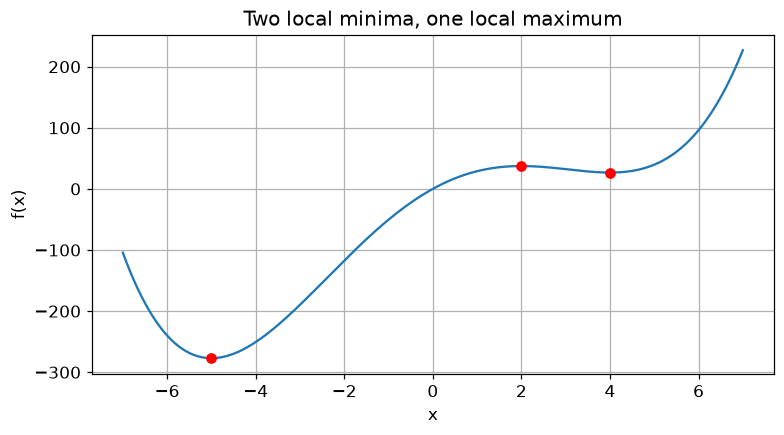

In [3]:
lecture_quartic = lambda x: x**4/4 - x**3/3 - 11*x*x + 40*x
lecture_curvature = lambda x: 3*x*x - 2*x - 22
stationary = np.array([-5., 2., 4.])
print("x, f(x), curvature:")
print(np.column_stack((stationary, lecture_quartic(stationary), lecture_curvature(stationary))))
t = np.linspace(-7, 7, 500)
plt.plot(t, lecture_quartic(t)); plt.plot(stationary, lecture_quartic(stationary), 'ro')
plt.xlabel('x'); plt.ylabel('f(x)'); plt.title('Two local minima, one local maximum'); plt.show()

## 3. Types of optimization methods

| Method family | Information used in 1D | ND analogue |
|---|---|---|
| Gradient-free methods | $f(x)$ | $f(\mathbf x)$ |
| Gradient (first-derivative) methods | $f(x),f'(x)$ | $f(\mathbf x),\nabla f(\mathbf x)$ |
| Second-derivative methods | $f(x),f'(x),f''(x)$ | $f(\mathbf x),\nabla f(\mathbf x),H_f(\mathbf x)$ |

The lecture considers nonlinear, continuous, smooth objectives when derivatives are used. Golden Section Search does not require derivatives. Per-iteration cost and convergence rate must be considered together.

# III Optimization in 1D: Golden Section Search

## 1. Unimodality and the bracket invariant

A function is **unimodal** on $[a,b]$ in the lecture's minimization convention if it has a unique minimizer $x^*\in[a,b]$, decreases strictly on the left of $x^*$, and increases strictly on its right. For $x_1<x_2$ in the interval,
$$x_2<x^*\Rightarrow f(x_1)>f(x_2),\qquad x_1>x^*\Rightarrow f(x_1)<f(x_2).$$

**Invariant:** the retained interval contains the minimizer. This resembles bisection, but the comparison is between objective values, not signs of $f$.

Choose $a<x_1<x_2<b$. If $f(x_1)>f(x_2)$, discard $[a,x_1)$ and retain $[x_1,b]$. Otherwise retain $[a,x_2]$. Under strict unimodality, equality implies that the minimizer lies between the two points, so either of these larger retained intervals is safe. Multiple valleys can invalidate this discard logic.

<details>
<summary>Example: Use unimodality to discard an interval</summary>

Suppose $f$ is unimodal on $[a,b]$, with $a<x_1<x_2<b$, $f(x_1)=6.88$, and $f(x_2)=6.42$. Which interval must retain the minimum?

<details>
<summary>Solution</summary>

Since $f(x_1)>f(x_2)$, retain $\boxed{[x_1,b]}$. If the minimizer were left of $x_1$, strict increase to its right would force $f(x_1)<f(x_2)$, a contradiction. Values at $a,b$ are unnecessary for this comparison.

</details>
</details>

<details>
<summary>Example: Unique global minimum does not imply unimodality</summary>

The displayed practice graph decreases to a low valley near $x=-3$, increases to a peak near $x=-2$, decreases to a second valley near $x=-1$, and then increases. Is it unimodal on the entire displayed interval?

<details>
<summary>Solution</summary>

No. There are two separate valleys with a local maximum between them. Even if one valley is the unique global minimum, the function is not monotonically decreasing before that minimizer and monotonically increasing afterwards over the whole interval. A unique global minimum alone does not justify Golden Section Search on that whole interval.

</details>
</details>

## 2. Deriving the golden ratio and reusing evaluations

Let $h_k=b_k-a_k$ and choose
$$x_1=a_k+(1-\tau)h_k,\qquad x_2=a_k+\tau h_k,\qquad \tfrac12<\tau<1.$$
Either retained interval has width $h_{k+1}=\tau h_k$. Choose $\tau$ so an old interior point becomes an interior point in the next interval. For the left retained interval, require the old $x_1$ to equal the new $x_2$:
$$a+(1-\tau)h=a+\tau(\tau h)\Rightarrow1-\tau=\tau^2.$$
Thus
$$\boxed{\tau=\frac{\sqrt5-1}{2}\approx0.6180339887,\qquad1-\tau\approx0.3819660113.}$$
Two function values initialize the method. Each interval reduction reuses one old point and value, requiring only one new function evaluation. The same self-similarity holds for the right interval.

## 3. Algorithm and termination

Initialize $a<b$, $x_1=a+(1-\tau)(b-a)$, $x_2=a+\tau(b-a)$, $f_1=f(x_1)$, $f_2=f(x_2)$.

1. If $f_1>f_2$, set $a\leftarrow x_1$, then $x_1\leftarrow x_2$, $f_1\leftarrow f_2$. Recompute the new $x_2=a+\tau(b-a)$ and $f_2$.
2. Otherwise set $b\leftarrow x_2$, then $x_2\leftarrow x_1$, $f_2\leftarrow f_1$. Recompute the new $x_1=a+(1-\tau)(b-a)$ and $f_1$.
3. Stop when $b-a\le\varepsilon$, or report that the iteration limit was reached.

The order of reuse matters: all right-hand values in each branch refer to the previous state. The midpoint $\hat x=(a+b)/2$ then satisfies $|\hat x-x^*|\le(b-a)/2$.

<details>
<summary>Instructor diagrams: interval elimination and point reuse</summary>

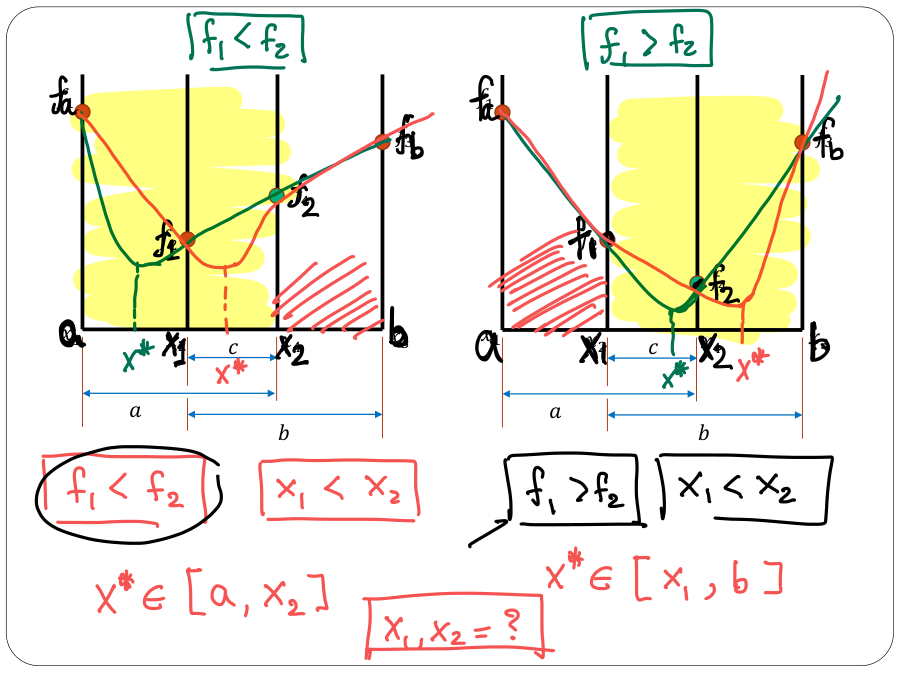

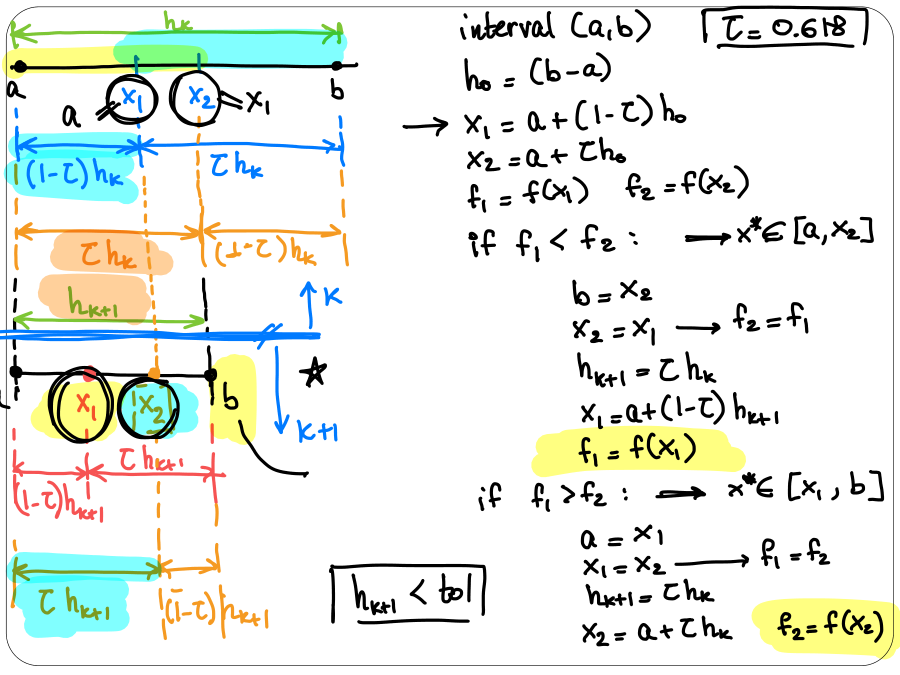

</details>

## 4. Convergence and evaluation cost

$$\boxed{h_k=\tau^kh_0,\qquad\frac{h_{k+1}}{h_k}=\tau.}$$
This is **linear convergence** of the enclosing interval width, with factor $\tau\approx0.618$. The midpoint error bound contracts by the same factor. The exact error ratio of an arbitrarily chosen representative point need not have limit $\tau$; the lecture's $e_k=h_k$ denotes an interval-based error measure.

For $h_k\le\varepsilon$, the required count is
$$k\ge\frac{\log(\varepsilon/h_0)}{\log\tau},\qquad k_{\min}=\max\left(0,\left\lceil\frac{\log(\varepsilon/h_0)}{\log\tau}\right\rceil\right).$$
For strict $h_k<\varepsilon$, use the floor plus one instead when $h_0\ge\varepsilon$. This implementation evaluates two initial points and one new value after each reduction, so it uses $2+k$ evaluations. A final independent evaluation of $f(\hat x)$ adds one. The rate is slower than bisection's width factor $1/2$, but bisection solves a root problem using a sign bracket, not an objective-value bracket.

<details>
<summary>Example: One Golden Section Search iteration</summary>

A unimodal objective is bracketed on $[-10,10]$. What is the retained width after one iteration?

<details>
<summary>Solution</summary>

$h_0=20$, so
$$h_1=\tau h_0=20\frac{\sqrt5-1}{2}\approx\boxed{12.36068}.$$
This is the interval width, not necessarily the actual error of a chosen iterate.

</details>
</details>

<details>
<summary>Example: Count Golden Section Search reductions</summary>

For $h_0=2$ and width tolerance $10^{-4}$, find the least number of reductions to obtain $h_k\le10^{-4}$. Count objective evaluations for the implementation above.

<details>
<summary>Solution</summary>

$$k_{\min}=\left\lceil\frac{\log(10^{-4}/2)}{\log((\sqrt5-1)/2)}\right\rceil=\boxed{21}.$$
There are $2+21=23$ objective evaluations in that implementation. A separate final objective evaluation would make $24$.

</details>
</details>

<details>
<summary>Example: Golden Section Search: assumptions, work, and rate</summary>

Which properties justify Golden Section Search? Assess these claims: (1) differentiability alone is enough; (2) unimodality on the interval of interest is enough for the discard logic; (3) it needs two new values every iteration; (4) it is derivative-free; (5) it is generically superlinear; (6) compared with Newton it is cheaper per iteration but slower under the lecture's usual assumptions.

<details>
<summary>Solution</summary>

Claims **2, 4, and 6** describe the lecture comparison. Differentiability does not exclude multiple valleys. Two initial values are needed, then one new value per interval reduction because one is reused. The width contracts linearly by $\tau\approx0.618$; Newton is locally quadratic at a nondegenerate solution. “Cheaper” is a per-step derivative-cost comparison, not a guarantee of lower total runtime for every objective.

</details>
</details>

## 5. Instructor polynomial experiment

The instructor's executable example is a different quartic:
$$f(x)=17.09x^4+9.79x^3+0.6317x^2+0.9324x+0.4565.$$
Its derivatives are
$$f'(x)=68.36x^3+29.37x^2+1.2634x+0.9324,\quad f''(x)=205.08x^2+58.74x+1.2634.$$
The original interval is $[-0.9,-0.2]$. We preserve these coefficients and evaluate the reference minimizer from $f'=0$ rather than treating the rounded value $-0.4549$ as exact.

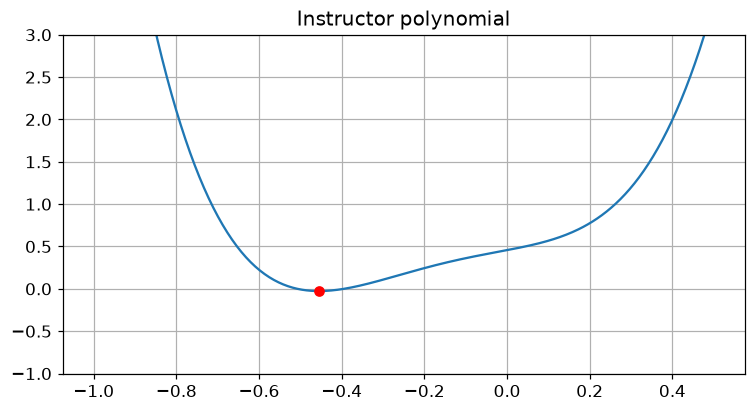

Reference minimizer: -0.45491835817326925 | f: -0.02668057317931316


In [4]:
a, b, c, d, e = 17.09, 9.79, 0.6317, 0.9324, 0.4565

def f(x):
    return a*x**4 + b*x**3 + c*x**2 + d*x + e

def df(x):
    return 4*a*x**3 + 3*b*x**2 + 2*c*x + d

def d2f(x):
    return 12*a*x**2 + 6*b*x + 2*c

roots_df = np.roots([4*a, 3*b, 2*c, d])
real_roots = roots_df[np.abs(roots_df.imag) < 1e-12].real
x_exact = float(real_roots[np.argmin(f(real_roots))])
assert abs(df(x_exact)) < 1e-12 and d2f(x_exact) > 0
xmesh = np.linspace(-1., .5, 400)
plt.plot(xmesh, f(xmesh)); plt.plot(x_exact, f(x_exact), 'ro')
plt.ylim(-1, 3); plt.title('Instructor polynomial'); plt.show()
print('Reference minimizer:', x_exact, '| f:', f(x_exact))

x: -0.4549185880324849 | bracket: (np.float64(-0.45491908054142394), np.float64(-0.4549180955235459)) | reductions: 28 | evaluations: 30


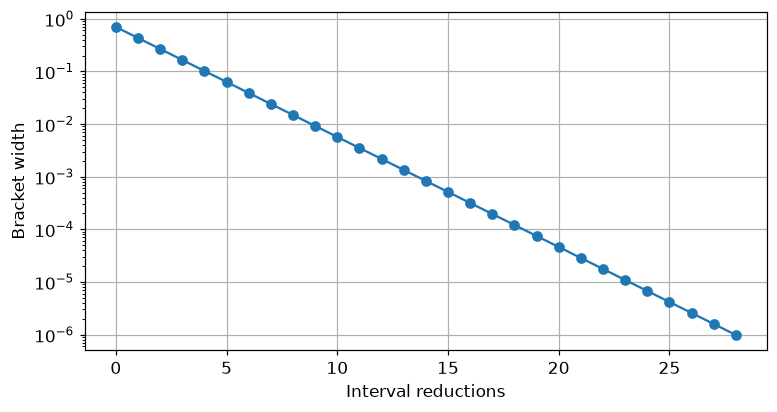

In [5]:
@dataclass(frozen=True)
class GoldenResult:
    x: float
    bracket: tuple
    widths: tuple
    nfev: int
    converged: bool

def golden_section(fun, left, right, tol=1e-6, maxiter=100):
    if not np.isfinite([left, right, tol]).all() or left >= right or tol <= 0:
        raise ValueError('Require finite left < right and positive tolerance.')
    if not isinstance(maxiter, int) or maxiter < 1:
        raise ValueError('maxiter must be a positive integer.')
    tau = (np.sqrt(5.) - 1.) / 2.
    x1, x2 = left + (1-tau)*(right-left), left + tau*(right-left)
    f1, f2 = float(fun(x1)), float(fun(x2))
    widths, nfev = (right-left,), 2
    for _ in range(maxiter):
        if not np.isfinite([f1, f2]).all():
            raise FloatingPointError('Nonfinite objective.')
        if right-left <= tol:
            break
        if f1 > f2:
            left, x1, f1 = x1, x2, f2
            x2 = left + tau*(right-left)
            f2 = float(fun(x2))
        else:
            right, x2, f2 = x2, x1, f1
            x1 = left + (1-tau)*(right-left)
            f1 = float(fun(x1))
        widths, nfev = widths + (right-left,), nfev+1
    if not np.isfinite([f1, f2]).all():
        raise FloatingPointError('Nonfinite objective.')
    return GoldenResult((left+right)/2, (left, right), widths, nfev, right-left <= tol)

golden_result = golden_section(f, -.9, -.2)
widths = np.array(golden_result.widths)
assert golden_result.converged
assert golden_result.bracket[0] <= x_exact <= golden_result.bracket[1]
assert abs(golden_result.x-x_exact) <= widths[-1]/2 + 1e-12
assert np.allclose(widths[1:]/widths[:-1], (np.sqrt(5)-1)/2)
assert golden_result.nfev == 2 + len(widths)-1
print('x:', golden_result.x, '| bracket:', golden_result.bracket, '| reductions:', len(widths)-1, '| evaluations:', golden_result.nfev)
plt.semilogy(widths, 'o-'); plt.xlabel('Interval reductions'); plt.ylabel('Bracket width'); plt.show()

The instructor loop initializes `count = 0` but never increments it; its nominal iteration cap therefore has no effect. The bounded `for` loop above enforces the cap and returns a convergence flag. It preserves the instructor's cached-value update and width history.

<details>
<summary>Example: Golden Section Search with an evaluation budget</summary>

Given a unimodal function and initial interval $[a,b]$, return the final endpoints when $b-a<10^{-5}$. Evaluate the objective only as often as necessary. What must the implementation cache?

<details>
<summary>Solution</summary>

Cache both interior locations and their two objective values. In the right-retained branch reuse $(x_2,f_2)$ as the new left interior point; in the left-retained branch reuse $(x_1,f_1)$ as the new right interior point. Evaluate only the newly introduced interior point. Use `while b-a >= 1e-5` for this strict stopping requirement, plus a practical iteration cap. The earlier generic lecture function uses a non-strict $\le$ tolerance; that is a deliberate distinction.

Plotting may evaluate the function on an array separately. Keep those visualization calls distinct from the algorithm's evaluation count. Recording bracket history before each update lets a plot show the interior point shared by consecutive brackets.

</details>
</details>

# IV Newton’s Method in 1D

## 1. Quadratic model and update

At $x_k$, approximate the objective by its second-order Taylor model:
$$q_k(x)=f(x_k)+f'(x_k)(x-x_k)+\tfrac12 f''(x_k)(x-x_k)^2.$$
Stationarity of this model gives
$$q_k'(x)=f'(x_k)+f''(x_k)(x-x_k)=0.$$
Hence
$$\boxed{s_k=-\frac{f'(x_k)}{f''(x_k)},\qquad x_{k+1}=x_k+s_k.}$$
When $f''(x_k)>0$, this is the minimizer of the quadratic model. For negative curvature it is instead the model's maximum. This method is exactly Newton root finding applied to $f'(x)=0$, using $f''$ as the derivative. Root finding for $f=0$ would use $f/f'$ instead, which solves a different problem.

<details>
<summary>Instructor diagrams: quadratic model and graphical Newton step</summary>

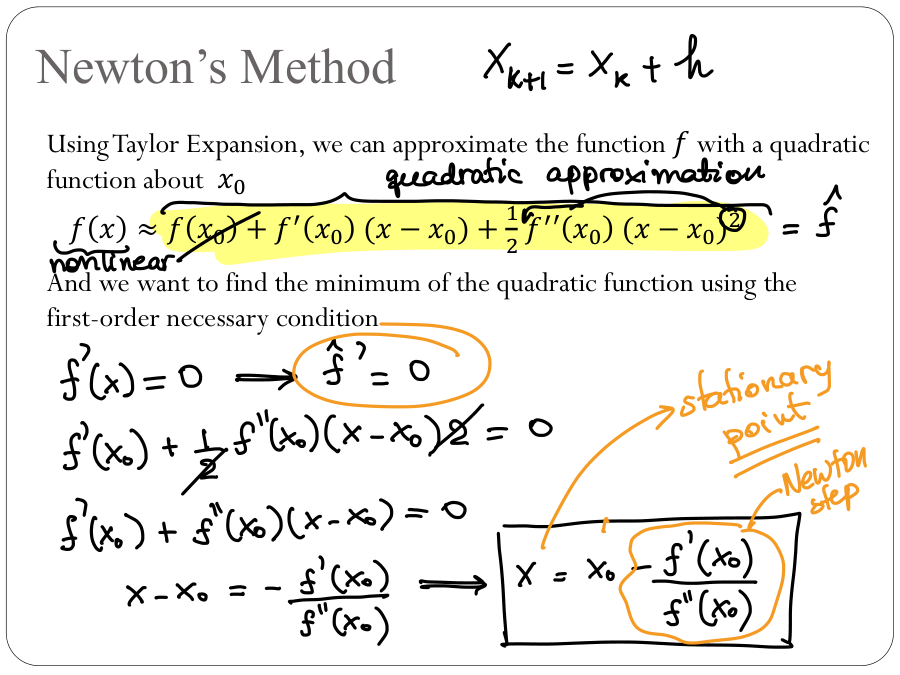

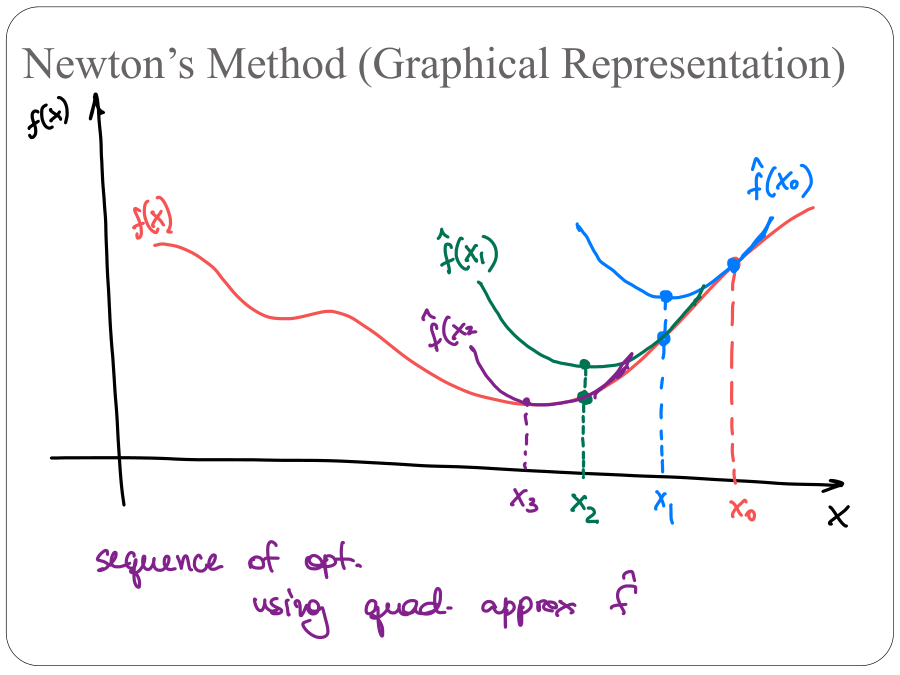

</details>

<details>
<summary>Example: Second-order Newton approximation</summary>

For $f(x)=3x^3+x^2+3x+1$ and $x_0=1$, express the quadratic model in terms of $h=x-x_0$.

<details>
<summary>Solution</summary>

$f(1)=8$, $f'(x)=9x^2+2x+3$, $f'(1)=14$, and $f''(x)=18x+2$, $f''(1)=20$.
$$\boxed{\widetilde f(h)=8+14h+10h^2.}$$
The factor $1/2$ in Taylor's formula is essential. Minimizing the model gives $h=-14/20=-0.7$, so the first Newton iterate is $x_1=0.3$. The model variable $h$ is a displacement, not the new coordinate $x$.

</details>
</details>

<details>
<summary>Example: Newton step for a Gaussian-shaped objective</summary>

For $f(x)=-e^{-x^2}$ and $x_0=0.25$, compute the next Newton optimization iterate.

<details>
<summary>Solution</summary>

$$f'(x)=2xe^{-x^2},\qquad f''(x)=2(1-2x^2)e^{-x^2}.$$
Therefore
$$x_{k+1}=x_k-\frac{x_k}{1-2x_k^2},\qquad x_1=\frac14-\frac{1/4}{7/8}=\boxed{-\frac1{28}\approx-0.0357143}.$$
At $x=\pm1/\sqrt2$, the curvature vanishes and the update is undefined. Newton is not a sign-bracketing method, so crossing the solution is allowed.

</details>
</details>

## 2. Local convergence and failure modes

If $f$ is sufficiently smooth, $f'(x^*)=0$, $f''(x^*)\ne0$, and $x_0$ is close enough, Newton has local at least quadratic convergence. With $e_k=x_k-x^*$,
$$e_{k+1}=\frac{f^{(3)}(x^*)}{2f''(x^*)}e_k^2+O(e_k^3).$$
If the leading coefficient is nonzero, the generic order is two; it can be higher or terminate exactly in special cases.

It requires first and second derivatives at each step. It can fail when $f''=0$, take a huge step when curvature is tiny, diverge from a poor start, or converge to a maximum or a stationary inflection point. A small step alone is not evidence of a minimum: inspect $|f'|$ and curvature after convergence. For $f=x^3$, Newton on $f'$ maps $x$ to $x/2$ and converges linearly to the stationary inflection at zero, where the nondegeneracy assumption fails.

<details>
<summary>Example: One Newton optimization step</summary>

For $f(x)=4x^3+2x^2+5x+40$ and $x_0=2$, compute $x_1$.

<details>
<summary>Solution</summary>

$$f'(x)=12x^2+4x+5,\qquad f''(x)=24x+4.$$
Thus $f'(2)=61$ and $f''(2)=52$, so
$$\boxed{x_1=2-\frac{61}{52}=\frac{43}{52}\approx0.826923.}$$
This is one step, not a certificate of an optimum. In fact $f'$ has negative discriminant $16-240<0$ and is positive everywhere; this cubic has no stationary point and is unbounded below.

</details>
</details>

## 3. Runnable Newton experiment and quadratic geometry

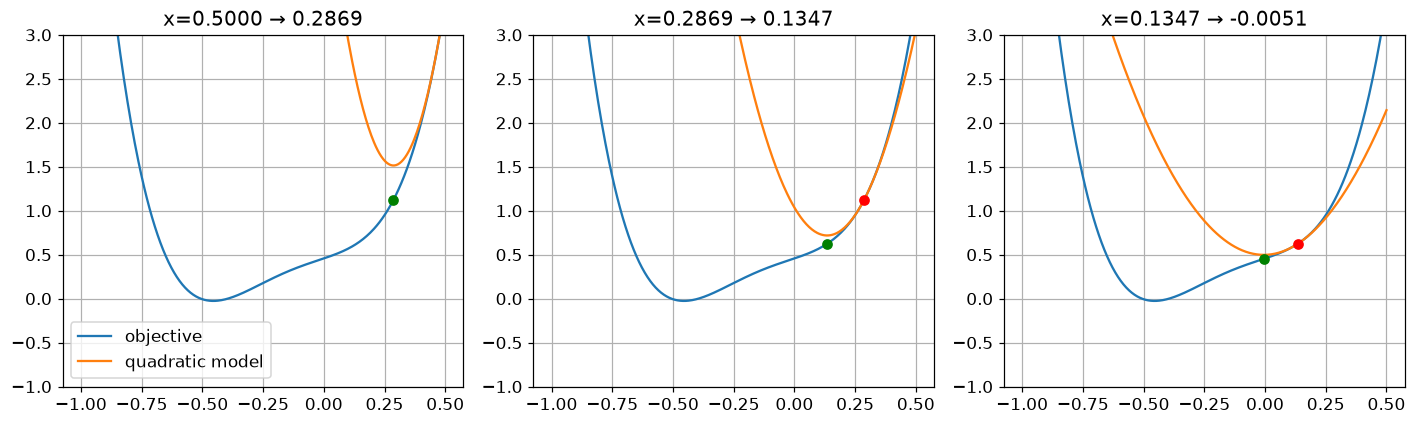

start: -0.1 | steps: 8 | x: -0.4549183581734239 | curvature: 16.982947781558074
start: 0.2 | steps: 27 | x: -0.45491835817326864 | curvature: 16.98294778153822
start: 0.5 | steps: 11 | x: -0.4549183581732686 | curvature: 16.982947781538215


In [6]:
@dataclass(frozen=True)
class ScalarResult:
    x: float
    history: tuple
    converged: bool

def newton_1d(grad, curvature, x0, tol=1e-10, maxiter=100):
    if not np.isfinite([x0, tol]).all() or tol <= 0 or not isinstance(maxiter, int) or maxiter < 1:
        raise ValueError('Invalid initial point or solver controls.')
    x, history = float(x0), (float(x0),)
    for _ in range(maxiter):
        g = float(grad(x))
        if not np.isfinite(g):
            raise FloatingPointError('Nonfinite derivative.')
        if abs(g) <= tol:
            return ScalarResult(x, history, True)
        h = float(curvature(x))
        if not np.isfinite(h) or h == 0:
            raise ValueError('Newton requires finite nonzero curvature.')
        xnew = x-g/h
        if not np.isfinite(xnew):
            raise FloatingPointError('Nonfinite Newton iterate.')
        x, history = xnew, history+(xnew,)
    return ScalarResult(x, history, abs(float(grad(x))) <= tol)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
x = .5
for ax in axes:
    xnew = x-df(x)/d2f(x)
    model = f(x)+df(x)*(xmesh-x)+.5*d2f(x)*(xmesh-x)**2
    ax.plot(xmesh, f(xmesh), label='objective')
    ax.plot(xmesh, model, label='quadratic model')
    ax.plot(x, f(x), 'ro'); ax.plot(xnew, f(xnew), 'go')
    ax.set(ylim=(-1, 3), title=f'x={x:.4f} → {xnew:.4f}')
    x = xnew
axes[0].legend(); fig.tight_layout(); plt.show()
for start in [-.1, .2, .5]:
    result = newton_1d(df, d2f, start)
    assert result.converged and abs(result.x-x_exact) < 1e-8
    print('start:', start, '| steps:', len(result.history)-1, '| x:', result.x, '| curvature:', d2f(result.x))

<details>
<summary>Example: Newton for a product involving a Gaussian</summary>

For $F(x)=-e^{-x^2}(x+\sin x)$, implement the first two derivatives and collect all Newton guesses starting with $x_0$, through the first iterate satisfying $|F'(x_k)|\le\mathrm{tol}$.

<details>
<summary>Solution</summary>

Let $u=x+\sin x$, $u'=1+\cos x$, and $u''=-\sin x$. Product rule gives
$$F'(x)=e^{-x^2}(2xu-u'),$$
$$F''(x)=e^{-x^2}\left[(2-4x^2)u+4xu'+\sin x\right].$$
Check $|F'|$ before each update. If the initial guess already meets the tolerance, the output contains exactly that one point. Otherwise append each new point, including the first accepted one. Add a maximum update count and reject zero curvature. The `newton_1d` helper already follows this history convention.

</details>
</details>

In [7]:
def practice_F(x):
    return -np.exp(-x*x)*(x+np.sin(x))

def practice_dF(x):
    return np.exp(-x*x)*(2*x*(x+np.sin(x))-1-np.cos(x))

def practice_d2F(x):
    return np.exp(-x*x)*((2-4*x*x)*(x+np.sin(x))+4*x*(1+np.cos(x))+np.sin(x))

practice_scalar = newton_1d(practice_dF, practice_d2F, .5, tol=1e-10)
assert practice_scalar.converged and practice_scalar.history[0] == .5
assert practice_d2F(practice_scalar.x) > 0
for x in [-.7, .2, .8]:
    h = 1e-5
    assert np.isclose(practice_dF(x), (practice_F(x+h)-practice_F(x-h))/(2*h), atol=1e-8)
    assert np.isclose(practice_d2F(x), (practice_dF(x+h)-practice_dF(x-h))/(2*h), atol=1e-8)
print('Gaussian-product guesses:', practice_scalar.history)

Gaussian-product guesses: (0.5, 0.6722581957293843, 0.6795403868223068, 0.67957865893932, 0.6795786600198815)


## 4. SciPy equivalents

The instructor explores `minimize`, `golden`, and the interactive help command `sopt.minimize?`. Here explicit method names and normal output make sequential execution reproducible.

`golden(..., brack=(a,b))` uses a two-point pair to start a downhill bracketing search; it does **not** constrain the answer to $[a,b]$. A valid three-point bracket includes a lower middle objective value. `minimize_scalar(..., bounds=(a,b), method='bounded')` constrains the scalar search to the interval, but uses bounded Brent rather than pure golden section. Compare the actual problem and method before comparing iteration counts.

API reference: [SciPy optimization tutorial](https://docs.scipy.org/doc/scipy/tutorial/optimize.html) and [minimize_scalar](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize_scalar.html).

In [8]:
scipy_1d = {
    'golden': sopt.golden(f, brack=(-8., 2.)),
    'bounded Brent': sopt.minimize_scalar(f, bounds=(-.9, -.2), method='bounded',
                                        options={'xatol': 1e-12}).x,
    'BFGS': sopt.minimize(lambda z: float(f(z[0])), np.array([2.]),
                          jac=lambda z: np.array([df(z[0])]), method='BFGS').x[0],
}
for name, value in scipy_1d.items():
    assert abs(value-x_exact) < 1e-6
    print(name, '| x:', value, '| f:', f(value))

golden | x: -0.454918360046204 | f: -0.02668057317931316
bounded Brent | x: -0.45491835793142693 | f: -0.02668057317931316
BFGS | x: -0.4549183560318975 | f: -0.02668057317931294


# V What is the optimal solution? (ND)

## 1. Taking derivatives: gradient and Hessian

For $f:\mathbb R^n\to\mathbb R$, the **gradient** is the column vector
$$\nabla f(\mathbf x)=\begin{bmatrix}\partial f/\partial x_1\\\vdots\\\partial f/\partial x_n\end{bmatrix}\in\mathbb R^{n\times1}.$$
The **Hessian** is
$$H_f(\mathbf x)=\nabla^2 f(\mathbf x),\qquad(H_f)_{ij}=\frac{\partial^2f}{\partial x_i\partial x_j}\in\mathbb R,\qquad H_f\in\mathbb R^{n\times n}.$$
Continuous second partial derivatives imply equality of mixed partials and hence symmetry: $H_f=H_f^T$. The Jacobian of the vector-valued function $\nabla f$ is the Hessian of the scalar-valued $f$.

## 2. Positive definiteness from linear algebra

For a real symmetric matrix $H$, suppose $v$ is an unit eigenvector for the Hessian matrix:

| Type | Quadratic form for all $\mathbf v\ne0$ | Eigenvalues |
|---|---|---|
| Positive definite (PD) | $\mathbf v^TH\mathbf v>0$ | all $\lambda_i>0$ |
| Positive semidefinite (PSD) | $\mathbf v^TH\mathbf v\ge0$ | all $\lambda_i\ge0$ |
| Negative definite (ND) | $\mathbf v^TH\mathbf v<0$ | all $\lambda_i<0$ |
| Negative semidefinite (NSD) | $\mathbf v^TH\mathbf v\le0$ | all $\lambda_i\le0$ |
| Indefinite | takes both positive and negative values | both signs occur |

For an eigenpair $H\mathbf v=\lambda\mathbf v$,
$$\mathbf v^TH\mathbf v=\lambda\|\mathbf v\|_2^2,\qquad\lambda=\frac{\mathbf v^TH\mathbf v}{\|\mathbf v\|_2^2}.$$
To prove the converse for all directions, use $H=Q\Lambda Q^T$: with $\mathbf z=Q^T\mathbf v$,
$$\mathbf v^TH\mathbf v=\sum_i\lambda_i z_i^2.$$
Use `la.eigvalsh(H)` for real symmetric Hessians. Looking only at positive diagonal entries is insufficient: $\begin{bmatrix}1&2\\2&1\end{bmatrix}$ has eigenvalues $3,-1$.

## 3. First-order necessary and second-order sufficient conditions

At an interior local minimizer of a differentiable objective,
$$\boxed{\nabla f(\mathbf x^*)=\mathbf0.}$$
If the Hessian exists at a local minimum, it is PSD. For $f\in C^2$ near a stationary point:
$$H_f(\mathbf x^*)\succ0\Rightarrow\text{strict local minimum},\quad H_f(\mathbf x^*)\prec0\Rightarrow\text{strict local maximum}.$$
An indefinite Hessian at a stationary point implies a **saddle point**. A singular semidefinite Hessian is inconclusive: $x^4+y^4$ has a strict minimum at zero; $x^4-y^4$ has a saddle there, but both have zero Hessian at zero.

Reason: near a stationary point, $f(\mathbf x^*+\mathbf s)-f(\mathbf x^*)=\tfrac12\mathbf s^TH_f(\mathbf x^*)\mathbf s+o(\|\mathbf s\|^2)$. Positive definiteness supplies positive curvature in every direction.

<details>
<summary>Example: Lecture ND stationary points</summary>

Find and classify stationary points of
$$f(x_1,x_2)=2x_1^3+4x_2^2+2x_2-24x_1.$$

<details>
<summary>Solution</summary>

$$\nabla f=\begin{bmatrix}6x_1^2-24\\8x_2+2\end{bmatrix},\qquad H_f=\begin{bmatrix}12x_1&0\\0&8\end{bmatrix}.$$
Stationarity gives $x_1=\pm2$, $x_2=-1/4$.
At $(2,-1/4)$, the Hessian is $\operatorname{diag}(24,8)$, so this is a strict local minimum. At $(-2,-1/4)$, it is $\operatorname{diag}(-24,8)$, so this is a saddle, not a maximum. The objective tends to $-\infty$ as $x_1\to-\infty$ with $x_2$ fixed, so the local minimum is not global and no global minimum exists.

</details>
</details>

<details>
<summary>Example: Semidefinite does not settle the classification</summary>

At zero, classify $f(x,y)=x^4+y^2$ and $g(x,y)=x^4-y^4$ using direct signs. What does each Hessian test say?

<details>
<summary>Solution</summary>

$f\ge0$, with equality only at zero, so zero is a strict global minimum. Its Hessian there is $\operatorname{diag}(0,2)$, PSD but not PD. For $g$, along the $x$ axis values are positive and along the $y$ axis negative, so zero is a saddle; its Hessian is zero. Semidefinite or zero Hessians require further analysis.

</details>
</details>

# VI Optimization in ND: Steepest Descent Method

## 1. Why the negative gradient is steepest

The directional derivative in a unit direction $\mathbf u$ is
$$D_{\mathbf u}f(\mathbf x)=\nabla f(\mathbf x)^T\mathbf u.$$
Cauchy–Schwarz gives $\nabla f^T\mathbf u\ge-\|\nabla f\|_2$ for $\|\mathbf u\|_2=1$, with equality at $\mathbf u=-\nabla f/\|\nabla f\|_2$ when the gradient is nonzero. Thus the steepest direction under the **Euclidean norm** is the negative gradient. The unnormalized choice is
$$\boxed{\mathbf s_k=-\nabla f(\mathbf x_k),\qquad\mathbf x_{k+1}=\mathbf x_k+\alpha_k\mathbf s_k.}$$
Since $\nabla f^T\mathbf s_k=-\|\nabla f\|_2^2<0$, a sufficiently small positive step decreases $f$. A large positive step can overshoot. At a stationary point there is no nonzero negative-gradient direction, even if the point is a saddle.

<details>
<summary>Example: Overshoot and the best step size</summary>

For $f(x_1,x_2)=(x_1-1)^2+(x_2-1)^2$ and $\mathbf x_0=(3,3)^T$, compare $\alpha=1$ with the optimal line-search step.

<details>
<summary>Solution</summary>

$\nabla f(\mathbf x_0)=(4,4)^T$. A unit step gives $\mathbf x_1=(-1,-1)^T$, with $f(\mathbf x_1)=8=f(\mathbf x_0)$: no decrease. Along the negative gradient,
$$\phi(\alpha)=f((3,3)^T-\alpha(4,4)^T)=2(2-4\alpha)^2.$$
Its minimum occurs at $\alpha=1/2$, giving $\boxed{\mathbf x_1=(1,1)^T}$ in one iteration. Direction and step length are separate decisions.

</details>
</details>

## 2. Line Search algorithm and orthogonality

**Algorithm:** initialize $\mathbf x_0$. At iteration $k$,
$$\mathbf s_k=-\nabla f(\mathbf x_k),\qquad\alpha_k\in\operatorname*{arg\,min}_{\alpha\ge0}f(\mathbf x_k+\alpha\mathbf s_k),\qquad\mathbf x_{k+1}=\mathbf x_k+\alpha_k\mathbf s_k.$$
The line search is a scalar optimization problem; Golden Section Search can solve it if the chosen interval is unimodal and contains its minimizer. Each outer step can therefore require several objective evaluations.

Write $\mathbf g_k=\nabla f(\mathbf x_k)$ and $\phi(\alpha)=f(\mathbf x_k-\alpha\mathbf g_k)$. Chain rule gives
$$\phi'(\alpha)=-\nabla f(\mathbf x_k-\alpha\mathbf g_k)^T\mathbf g_k.$$
At a differentiable **interior exact** line minimizer, $\phi'(\alpha_k)=0$, hence
$$\boxed{\nabla f(\mathbf x_{k+1})^T\nabla f(\mathbf x_k)=0.}$$
Consecutive nonzero gradients, and thus steepest directions, are orthogonal. This helps explain the zig-zag path on elongated contours. Approximate or boundary line searches do not guarantee exact orthogonality.

<details>
<summary>Example: Direction of the first gradient descent step</summary>

For $f(x_1,x_2)=10x_1^3-x_2^2+x_1-1$ at $(2,2)^T$, find the first steepest descent direction.

<details>
<summary>Solution</summary>

$$\nabla f=\begin{bmatrix}30x_1^2+1\\-2x_2\end{bmatrix},\qquad\boxed{\mathbf s_0=-\nabla f(2,2)=\begin{bmatrix}-121\\4\end{bmatrix}.}$$
This is the unnormalized direction. The next iterate additionally needs $\alpha_0$: $\mathbf x_1=(2,2)^T+\alpha_0(-121,4)^T$. The normalized steepest unit direction divides this vector by $\sqrt{121^2+4^2}$.

</details>
</details>

<details>
<summary>Instructor diagrams: negative gradient and line-search geometry</summary>

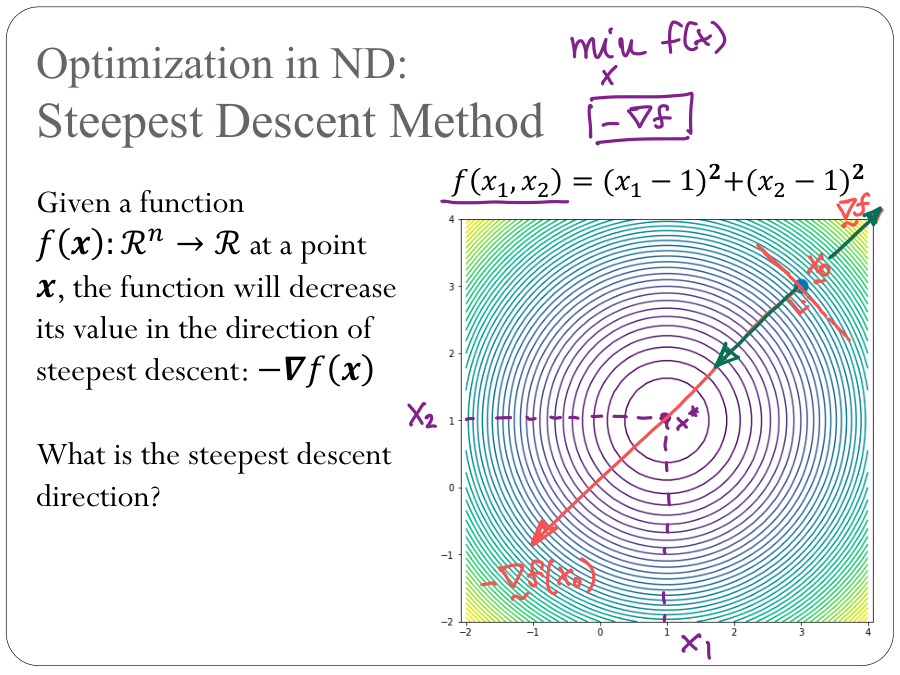

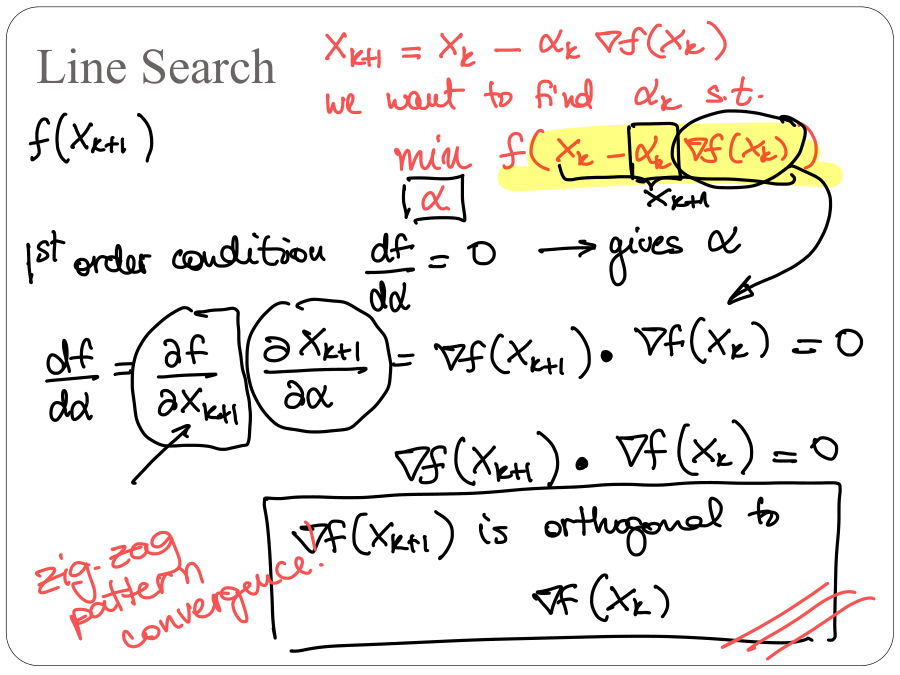

</details>

## 3. Rate, conditioning, and stopping

For a strongly convex quadratic $f(\mathbf x)=\tfrac12\mathbf x^TQ\mathbf x-\mathbf b^T\mathbf x+c$ with symmetric $Q\succ0$, exact line search gives
$$\alpha_k=\frac{\mathbf g_k^T\mathbf g_k}{\mathbf g_k^TQ\mathbf g_k}.$$
Let $\kappa=\lambda_{\max}(Q)/\lambda_{\min}(Q)$. In the $Q$-norm,
$$\|\mathbf e_{k+1}\|_Q\le\frac{\kappa-1}{\kappa+1}\|\mathbf e_k\|_Q.$$
Thus steepest descent is generally linearly convergent in this setting, and large condition numbers can cause slow zig-zag motion. This statement is not a global guarantee for arbitrary nonconvex functions.

Stop on a small gradient norm for unconstrained stationarity, while also enforcing iteration limits and detecting nonfinite values. A small objective change alone can mean stagnation far from a minimizer. A small gradient still does not classify a stationary point; inspect curvature when needed.

# VII Newton’s Method in ND

## 1. Quadratic model and linear system

The second-order Taylor approximation is
$$f(\mathbf x_k+\mathbf s)\approx q_k(\mathbf s)=f(\mathbf x_k)+\nabla f(\mathbf x_k)^T\mathbf s+\tfrac12\mathbf s^TH_f(\mathbf x_k)\mathbf s.$$
Differentiate with respect to $\mathbf s$ and impose stationarity:
$$\nabla_{\mathbf s}q_k=\nabla f(\mathbf x_k)+H_f(\mathbf x_k)\mathbf s=\mathbf0.$$
The Newton algorithm is
$$\boxed{H_f(\mathbf x_k)\mathbf s_k=-\nabla f(\mathbf x_k),\qquad\mathbf x_{k+1}=\mathbf x_k+\mathbf s_k.}$$
The Hessian contains curvature information that determines both direction and step scale. Solve the linear system with `la.solve(H, -g)`; do not form $H^{-1}$ explicitly. A positive definite Hessian makes the quadratic model strictly convex; an invertible indefinite Hessian gives a stationary model point but not its minimum.

<details>
<summary>Instructor diagrams: multivariate quadratic model and Newton algorithm</summary>

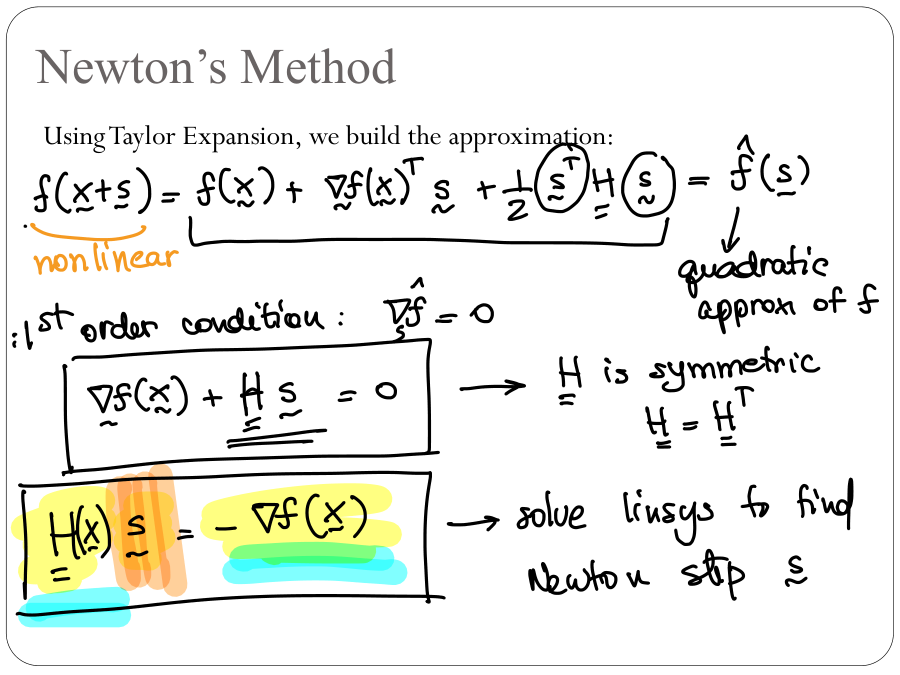

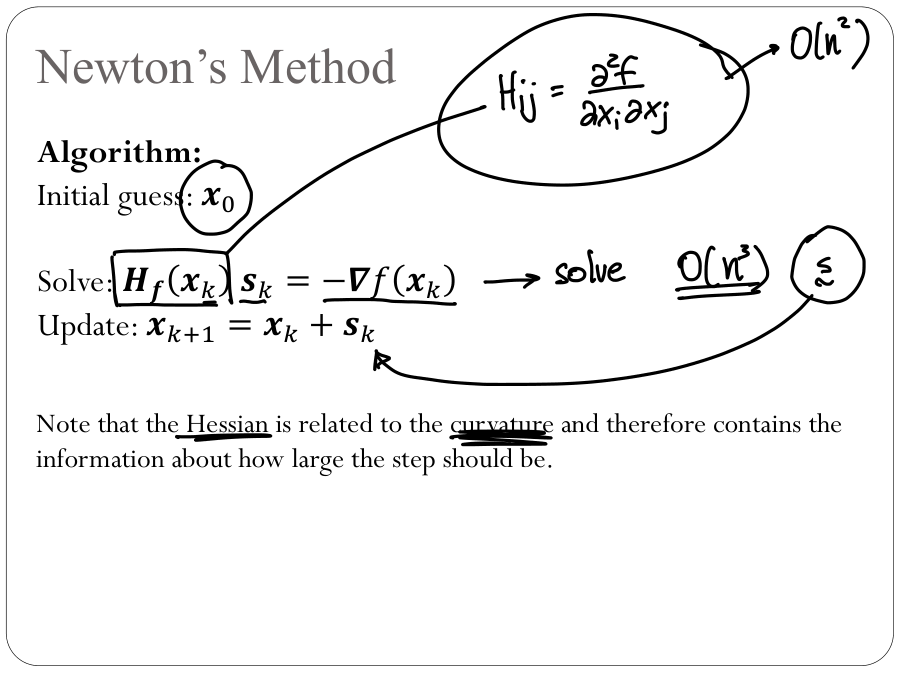

</details>

<details>
<summary>Example: One Newton step for a coupled quadratic</summary>

For $f(x,y)=21x^2-6x+6+15y^2-xy$ and $\mathbf x_0=(1,2)^T$, how many full Newton steps find the minimum?

<details>
<summary>Solution</summary>

$$\nabla f=\begin{bmatrix}42x-y-6\\30y-x\end{bmatrix},\qquad H=\begin{bmatrix}42&-1\\-1&30\end{bmatrix}.$$
Its leading principal minors are $42>0$ and $1260-1=1259>0$, so $H\succ0$. Solve $H\mathbf x^*=(6,0)^T$:
$$\mathbf x^*=\left(\frac{180}{1259},\frac6{1259}\right)^T.$$
The exact quadratic model gives this solution in **one** Newton step from the given nonoptimal start.

</details>
</details>

<details>
<summary>Example: Newton direction versus next point</summary>

For $f(\mathbf x)=0.5x_1^2+2x_1x_2+7x_2^2$ and $\mathbf x_0=(3,5)^T$, find $\mathbf s_0$ in $\mathbf x_1=\mathbf x_0+\mathbf s_0$.

<details>
<summary>Solution</summary>

$$\nabla f=\begin{bmatrix}x_1+2x_2\\2x_1+14x_2\end{bmatrix},\quad H=\begin{bmatrix}1&2\\2&14\end{bmatrix},\quad\nabla f(3,5)=\begin{bmatrix}13\\76\end{bmatrix}.$$
Since $H\mathbf x_0=\nabla f(\mathbf x_0)$, solving $H\mathbf s_0=-\nabla f$ gives $\boxed{\mathbf s_0=(-3,-5)^T}$. The next point is $(0,0)^T$. The direction and next point are different vectors.

</details>
</details>

<details>
<summary>Example: Exponential and trigonometric cross terms</summary>

For
$$f(x,y)=10x^2+6xy+10y^2+11e^{4xy}+3\sin^2y+9\cos(xy),$$
at $\mathbf x_0=(0,1)^T$, compute the gradient, Hessian, first Newton point, and steepest direction.

<details>
<summary>Solution</summary>

Apply the product and chain rules before substituting the point. Set $E=e^{4xy}$, $S=\sin(xy)$, and $C=\cos(xy)$. Then
$$f_x=20x+6y+44yE-9yS,$$
$$f_y=6x+20y+44xE+3\sin(2y)-9xS.$$
The Hessian entries are
$$f_{xx}=20+176y^2E-9y^2C,$$
$$f_{xy}=6+44E+176xyE-9S-9xyC,$$
$$f_{yy}=20+176x^2E+6\cos(2y)-9x^2C.$$
Thus
$$\mathbf g_0=\begin{bmatrix}50\\20+3\sin2\end{bmatrix}\approx\begin{bmatrix}50\\22.72789228\end{bmatrix},\quad H_0=\begin{bmatrix}187&50\\50&20+6\cos2\end{bmatrix}\approx\begin{bmatrix}187&50\\50&17.50311898\end{bmatrix}.$$
Newton solves $H_0\mathbf s_0=-\mathbf g_0$, giving
$$\boxed{\mathbf x_1\approx(0.3379178959,-1.2638129307)^T}.$$
Steepest descent uses $\boxed{\mathbf s_0=-\mathbf g_0=(-50,-22.72789228)^T}$. A step length is still needed for its next point.

</details>
</details>

## 2. Summary: convergence, cost, and curvature risks

The lecture summary states: typical quadratic convergence, second derivatives required, local convergence from a sufficiently close initial guess, poor behavior when the Hessian is “nearly indefinite,” and $O(n^3)$ work per dense linear solve.

More precisely, a locally Lipschitz Hessian, a nondegenerate stationary solution, and a sufficiently close start yield local quadratic convergence. To converge to a nondegenerate minimum the limiting Hessian is PD. A full Newton step does not guarantee global descent.

If $H\succ0$ and $\mathbf g\ne0$, then $\mathbf g^T\mathbf s=-\mathbf g^TH^{-1}\mathbf g<0$. For indefinite $H$, this quantity may be positive, giving an ascent direction. A **nearly singular** Hessian instead produces an ill-conditioned linear solve and potentially very large steps. These are distinct issues behind the lecture's informal “nearly indefinite” warning. Damping, line search, trust regions, or Hessian modification can improve robustness; the classroom code below deliberately uses full Newton steps.

Dense Hessian storage is $O(n^2)$, and its evaluation cost depends on the objective. $O(n^3)$ describes a general dense factorization, not every possible structured Newton implementation.

<details>
<summary>Example: How many Newton iterations for the lecture quadratic?</summary>

For $f(x,y)=0.5x^2+2.5y^2$, estimate the number of full Newton iterations to reach the minimizer from a nonoptimal starting point.

<details>
<summary>Solution</summary>

$$\nabla f=(x,5y)^T,\qquad H=\operatorname{diag}(1,5).$$
Solving $H\mathbf s=-\nabla f$ gives $\mathbf s=-(x,y)^T$. Therefore $\boxed{\mathbf x_1=(0,0)^T}$ in one update in exact arithmetic. If the initial point is already the minimizer, zero updates are needed. Every strictly convex quadratic has an exact quadratic Taylor model and the same one-step property for full Newton.

</details>
</details>

<details>
<summary>Example: A quadratic can have a minimum, maximum, or saddle</summary>

Let $f(x,y)=p_1(x)+p_2(y)$, where each $p_i$ is quadratic. Assume there is exactly one stationary point. What does full Newton do?

<details>
<summary>Solution</summary>

Write $f(\mathbf x)=\frac12\mathbf x^TH\mathbf x+\mathbf b^T\mathbf x+c$. Uniqueness of its stationary point implies $H$ is invertible. Newton gives
$$\mathbf x_1=\mathbf x_0-H^{-1}(H\mathbf x_0+\mathbf b)=-H^{-1}\mathbf b.$$
It reaches the stationary point in one update from any nonstationary starting point, even if that point is a maximum or saddle. Classification depends on $H$: positive definite, negative definite, or indefinite. A Newton solve alone does not identify a minimum.

</details>
</details>

<details>
<summary>Example: A Newton step can be ascent</summary>

For $f(x,y)=-x^2/2+y^2/2$, take a Newton step from $(1,0)^T$. Is its direction descent?

<details>
<summary>Solution</summary>

$\nabla f=(-1,0)^T$ and $H=\operatorname{diag}(-1,1)$. Thus $\mathbf s=(-1,0)^T$ and $\mathbf g^T\mathbf s=1>0$: it is ascent. The update reaches the saddle $(0,0)^T$, increasing the objective from $-1/2$ to $0$. An invertible Hessian alone does not make Newton an optimization descent method.

</details>
</details>

<details>
<summary>Example: What Newton and steepest descent have in common</summary>

Which information do both methods evaluate at an iteration: gradient, Hessian, exact line search, or a generally superlinear convergence model?

<details>
<summary>Solution</summary>

Both evaluate the **gradient**. The classroom Newton method additionally needs a Hessian but takes a full step without a line search. Steepest descent uses a gradient direction and a selected step length; its usual quadratic-case rate is linear, not generally superlinear.

</details>
</details>

# VIII Instructor ND experiments: three objectives and two methods

## 1. Functions, gradients, and Hessians

The instructor compares:

1. **Function 1:** $f_1(x,y)=0.5x^2+2.5y^2$, minimizer $(0,0)$, Hessian $\operatorname{diag}(1,5)$.
2. **Function 2:** $f_2(x,y)=(x-1)^2+(y-1)^2$, minimizer $(1,1)$, Hessian $2I$.
3. **Function 3 (Rosenbrock):** $f_3(x,y)=100(y-x^2)^2+(1-x)^2$, unique global minimizer $(1,1)$ with value zero. Its curved narrow valley makes steepest descent slow.

For Rosenbrock,
$$\nabla f_3=\begin{bmatrix}-400x(y-x^2)+2(x-1)\\200(y-x^2)\end{bmatrix},\quad H_3=\begin{bmatrix}1200x^2-400y+2&-400x\\-400x&200\end{bmatrix}.$$
A sum of squares establishes $f_3\ge0$ and identifies its global minimum, but does not make $f_3$ globally convex.

In [9]:
def f1(x):
    return .5*x[0]**2 + 2.5*x[1]**2

def df1(x):
    return np.array([x[0], 5*x[1]])

def ddf1(x):
    return np.diag([1., 5.])

def f2(x):
    return (x[0]-1)**2 + (x[1]-1)**2

def df2(x):
    return 2*(np.asarray(x)-1)

def ddf2(x):
    return 2*np.eye(2)

def f3(X):
    x, y = X
    return 100*(y-x*x)**2 + (1-x)**2

def df3(X):
    x, y = X
    return np.array([-400*x*(y-x*x)+2*(x-1), 200*(y-x*x)])

def ddf3(X):
    x, y = X
    return np.array([[1200*x*x-400*y+2, -400*x], [-400*x, 200.]])

## 2. Reusable plotting helpers

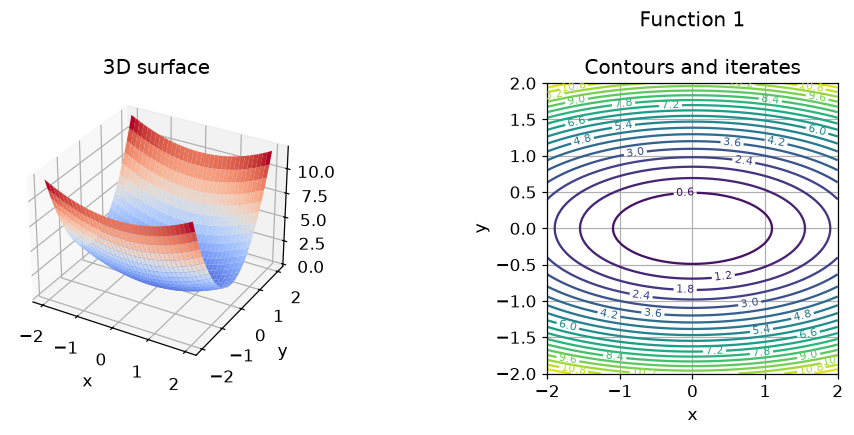

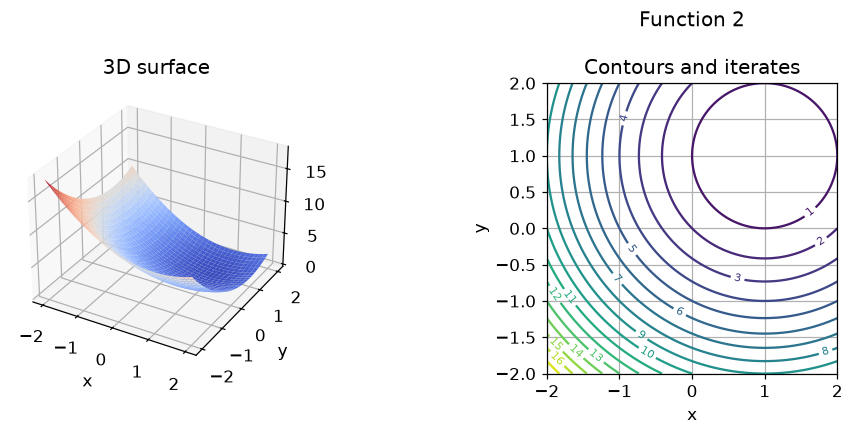

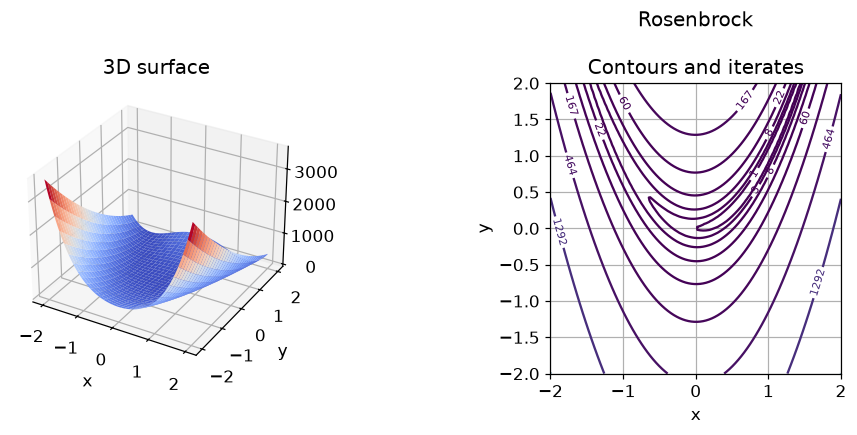

In [10]:
def plotFunction(fun, interval=(-2, 2), levels=20, steps=None, fhist=None, title='Objective'):
    left, right = interval
    xx, yy = np.mgrid[left:right:100j, left:right:100j]
    zz = fun(np.array([xx, yy]))
    fig = plt.figure(figsize=(14, 4))
    ax = fig.add_subplot(131, projection='3d')
    ax.plot_surface(xx, yy, zz, cmap='coolwarm', rstride=3, cstride=3)
    ax.set(xlabel='x', ylabel='y', title='3D surface')
    ax = fig.add_subplot(132)
    contours = ax.contour(xx, yy, zz, levels=levels)
    ax.clabel(contours, fontsize=7)
    if steps is not None:
        path = np.asarray(steps)
        ax.plot(path[:, 0], path[:, 1], 'o-', ms=3, lw=1)
    ax.set(xlabel='x', ylabel='y', aspect='equal', title='Contours and iterates')
    if fhist is not None:
        ax = fig.add_subplot(133)
        values = np.asarray(fhist)
        ax.semilogy(np.maximum(values, np.finfo(float).tiny), '.-')
        ax.set(xlabel='Updates', ylabel='max(f, tiny)', title='Objective history')
    fig.suptitle(title); fig.tight_layout(); plt.show()

def plotConvergence(steps, exact, r):
    error = la.norm(np.asarray(steps)-np.asarray(exact), axis=1)
    valid = (error[:-1] > 1e-12) & (error[1:] > 1e-14)
    indices = np.arange(len(error)-1)[valid]
    ratio = error[1:][valid]/error[:-1][valid]**r
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].semilogy(np.maximum(error, np.finfo(float).tiny), '.-')
    axes[0].set(xlabel='Updates', ylabel='True error norm')
    axes[1].plot(indices, ratio, 'o-')
    axes[1].set(xlabel='k', ylabel=f'e[k+1] / e[k]**{r}')
    fig.tight_layout(); plt.show()

for fun, name in [(f1, 'Function 1'), (f2, 'Function 2'), (f3, 'Rosenbrock')]:
    plotFunction(fun, levels=np.logspace(0, 4, 10) if fun is f3 else 20, title=name)

## 3. Robust solver implementations

The implementations below stop using the gradient norm, update the current point before testing, and count completed updates. The golden line search and full Newton linear solve remain the core methods.

The ND golden search first uses SciPy's downhill bracketing routine on the ray. This keeps the derivative-free scalar search while making its bracket explicit. The polynomial and Rosenbrock experiments below admit these searches; an arbitrary nonconvex or unbounded ray need not. Such a search reports a failure rather than a false optimum. Finite iteration limits remain essential.

**Floating-point precision guard:** near a stationary point, line-search objective values can round to exactly the same number, even while the gradient exceeds the target. If a trial objective difference is at roundoff scale, or the downhill bracket is not strict enough for SciPy golden search, the implementation uses the available gradient to bracket and solve the directional-derivative equation with Brent root finding. This guard adds gradient evaluations and does not relax the stopping tolerance.

In [11]:
@dataclass(frozen=True)
class NDResult:
    x: np.ndarray
    steps: tuple
    fhist: tuple
    nit: int
    grad_norm: float
    converged: bool

def validate_nd(x0, tol, maxiter):
    x = np.array(x0, dtype=float, copy=True)
    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError('Initial point must be a finite nonempty vector.')
    if not np.isfinite(tol) or tol <= 0 or not isinstance(maxiter, int) or maxiter < 1:
        raise ValueError('Invalid tolerance or iteration limit.')
    return x

def checked_gradient(grad, x):
    g = np.asarray(grad(x), dtype=float)
    if g.shape != x.shape or not np.isfinite(g).all():
        raise ValueError('Gradient shape or values invalid.')
    return g

def precision_line_search(fun, grad, x, s):
    line = lambda t: float(fun(x+t*s))
    scale = min(1., 1./la.norm(s))
    f0, fs = line(0.), line(scale)
    roundoff = 32*np.finfo(float).eps*max(1., abs(f0))
    if abs(fs-f0) > roundoff:
        bracket = sopt.bracket(line, xa=0., xb=scale, maxiter=100)
        if bracket[4] < bracket[3] and bracket[4] < bracket[5]:
            return float(sopt.golden(line, brack=bracket[:3], tol=1e-9, maxiter=200))
    # Use directional derivatives when objective differences lose precision.
    dline = lambda t: float(checked_gradient(grad, x+t*s) @ s)
    right = 1.
    for _ in range(40):
        if dline(right) >= 0:
            return float(sopt.brentq(dline, 0., right, xtol=1e-12))
        right *= 2
    raise RuntimeError('Cannot bracket a stationary line-search point.')

def steepestDescent(fun, grad, x0, maxiter=1000, tol=1e-6, alpha=0):
    x = validate_nd(x0, tol, maxiter)
    if not np.isfinite(alpha) or alpha < 0:
        raise ValueError('alpha must be nonnegative; zero requests line search.')
    initial_value = float(fun(x))
    if not np.isfinite(initial_value):
        raise FloatingPointError('Nonfinite initial objective.')
    steps, fhist = (tuple(x),), (initial_value,)
    for _ in range(maxiter):
        g = checked_gradient(grad, x)
        if la.norm(g) <= tol:
            break
        s = -g
        if alpha == 0:
            step = precision_line_search(fun, grad, x, s)
            if not np.isfinite(step) or step <= 0:
                raise RuntimeError('Line search did not return a positive finite step.')
        else:
            step = alpha
        xnew = x+step*s
        value = float(fun(xnew))
        if not np.isfinite(xnew).all() or not np.isfinite(value):
            raise FloatingPointError('Nonfinite iterate or objective.')
        x, steps, fhist = xnew, steps+(tuple(xnew),), fhist+(value,)
    norm = float(la.norm(checked_gradient(grad, x)))
    return NDResult(x.copy(), steps, fhist, len(steps)-1, norm, norm <= tol)

def NewtonMethod(fun, grad, hess, x0, maxiter=50, tol=1e-8):
    x = validate_nd(x0, tol, maxiter)
    initial_value = float(fun(x))
    if not np.isfinite(initial_value):
        raise FloatingPointError('Nonfinite initial objective.')
    steps, fhist = (tuple(x),), (initial_value,)
    for _ in range(maxiter):
        g = checked_gradient(grad, x)
        if la.norm(g) <= tol:
            break
        H = np.asarray(hess(x), dtype=float)
        if H.shape != (x.size, x.size) or not np.isfinite(H).all():
            raise ValueError('Hessian shape or values invalid.')
        s = la.solve(H, -g)
        xnew = x+s
        value = float(fun(xnew))
        if not np.isfinite(xnew).all() or not np.isfinite(value):
            raise FloatingPointError('Nonfinite iterate or objective.')
        x, steps, fhist = xnew, steps+(tuple(xnew),), fhist+(value,)
    norm = float(la.norm(checked_gradient(grad, x)))
    return NDResult(x.copy(), steps, fhist, len(steps)-1, norm, norm <= tol)

## 4. Steepest descent on all instructor starting points

Function 1 | updates: 37 | x: [ 6.10454642e-07 -1.22090946e-07] | gradient: 8.633132948866674e-07 | converged: True


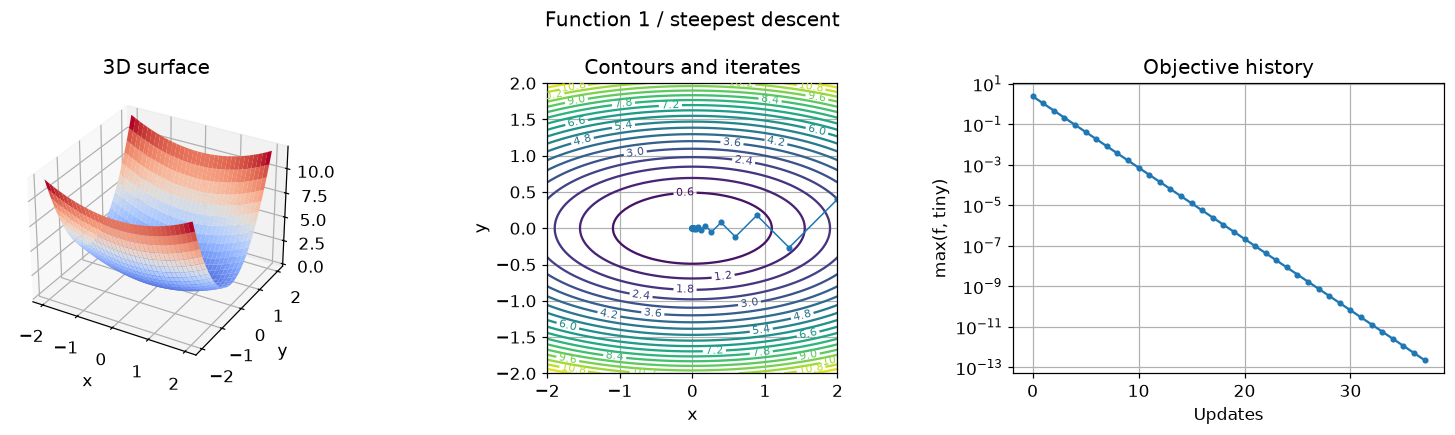

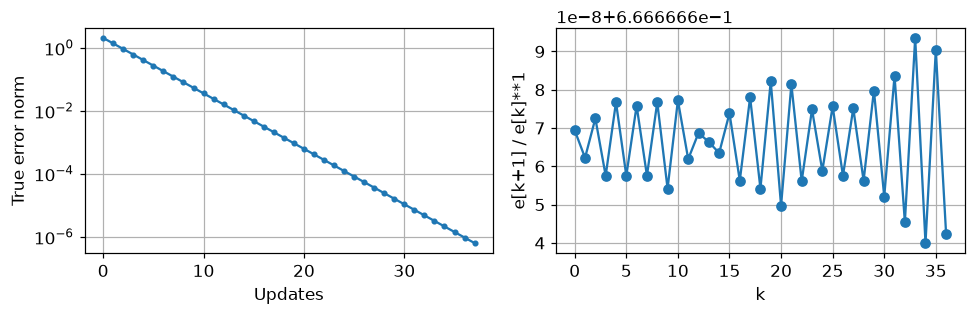

Function 2 | updates: 1 | x: [1. 1.] | gradient: 0.0 | converged: True


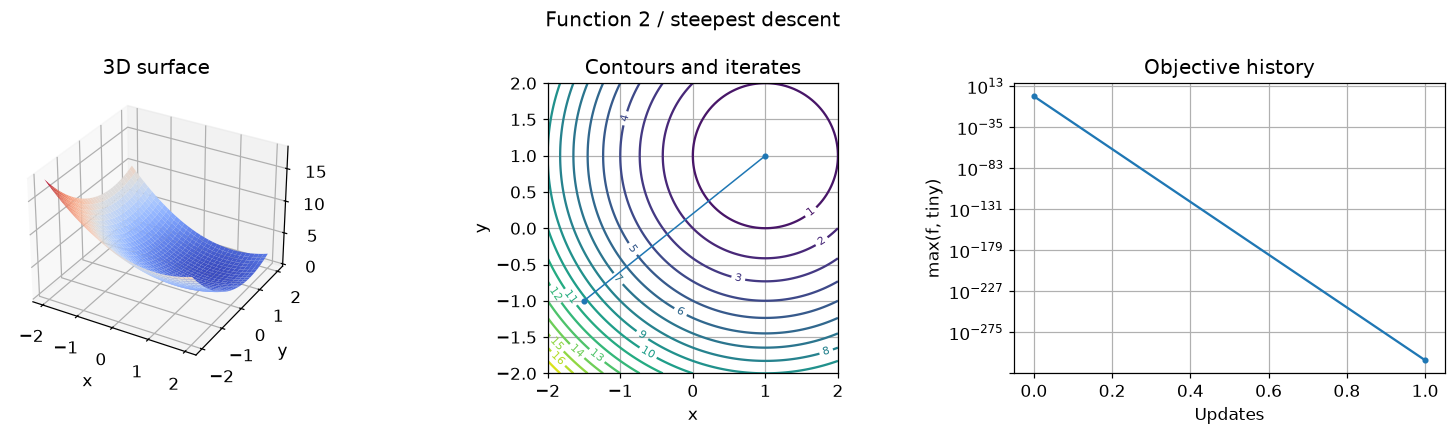

Rosenbrock A | updates: 1000 | x: [0.92446927 0.85423365] | gradient: 0.08195581620612064 | converged: False


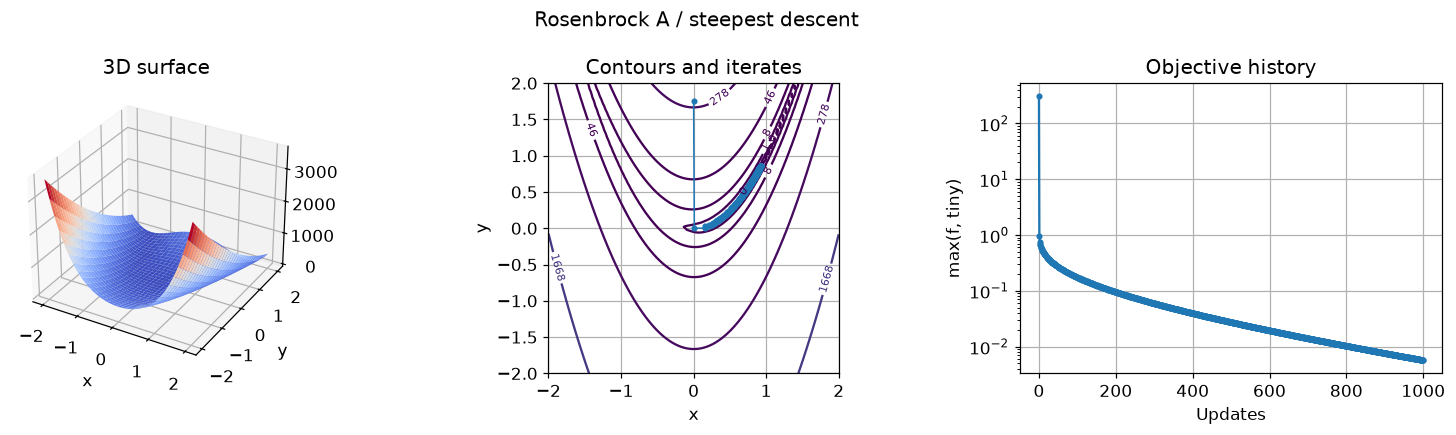

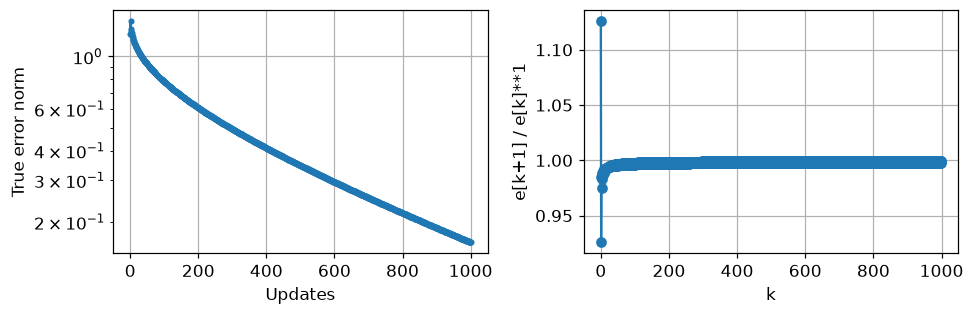

Rosenbrock B | updates: 1000 | x: [0.98839247 0.97688083] | gradient: 0.011050824476670548 | converged: False


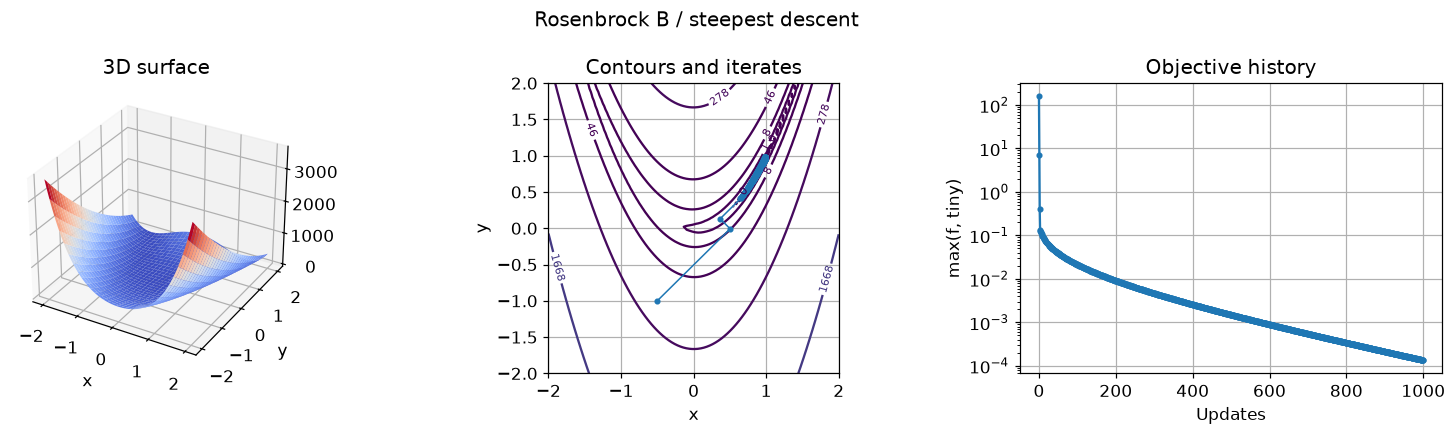

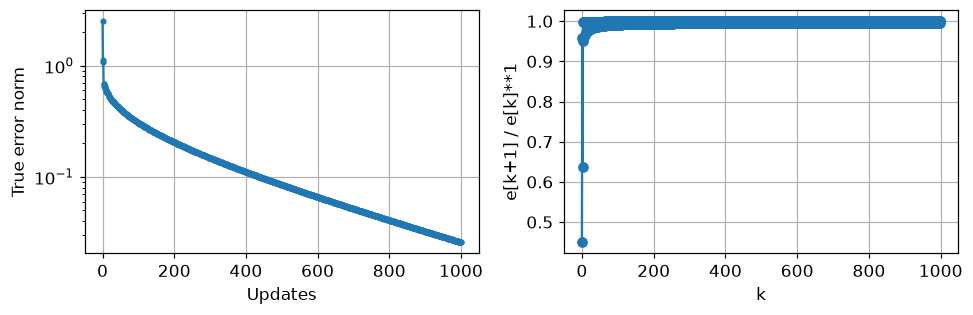

In [12]:
sd_cases = (
    ('Function 1', f1, df1, [2., 2./5], [0., 0.], 50),
    ('Function 2', f2, df2, [-1.5, -1.], [1., 1.], 50),
    ('Rosenbrock A', f3, df3, [0., 1.75], [1., 1.], 1000),
    ('Rosenbrock B', f3, df3, [-.5, -1.], [1., 1.], 1000),
)
sd_results = {}
for name, fun, grad, start, exact, limit in sd_cases:
    result = steepestDescent(fun, grad, start, maxiter=limit, tol=1e-6)
    sd_results = {**sd_results, name: result}
    print(name, '| updates:', result.nit, '| x:', result.x,
          '| gradient:', result.grad_norm, '| converged:', result.converged)
    assert np.isfinite(result.fhist).all()
    assert np.max(np.diff(result.fhist)) < 1e-8
    plotFunction(fun, steps=result.steps, fhist=result.fhist,
                 levels=np.logspace(-3, 4, 10) if fun is f3 else 20, title=name+' / steepest descent')
    if name != 'Function 2':
        plotConvergence(result.steps, exact, 1)
assert sd_results['Function 1'].converged and sd_results['Function 2'].converged

Read the printed convergence flag and gradient norm alongside the graph. The Rosenbrock runs may exhaust 1000 updates while still descending: this demonstrates slow progress rather than successful convergence. Ratios computed from a known exact solution are teaching diagnostics; a practical solver does not know that solution. Ignore ratios dominated by floating-point roundoff, and do not infer a rigorous asymptotic order from only a few transient points.

## 5. Newton on all instructor starting points

Function 1 | updates: 1 | x: [0. 0.] | gradient: 0.0


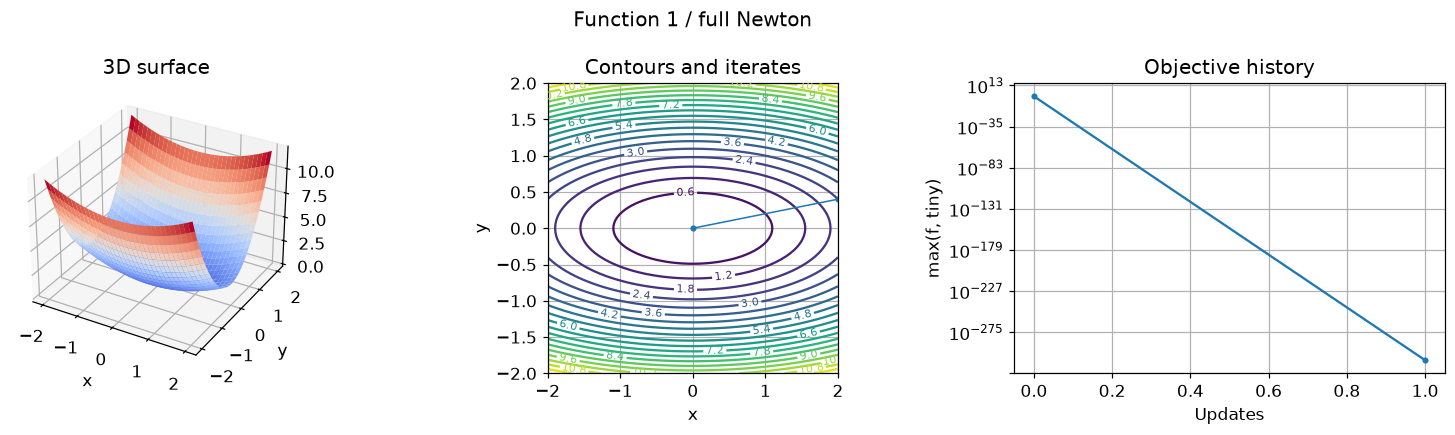

Function 2 | updates: 1 | x: [1. 1.] | gradient: 0.0


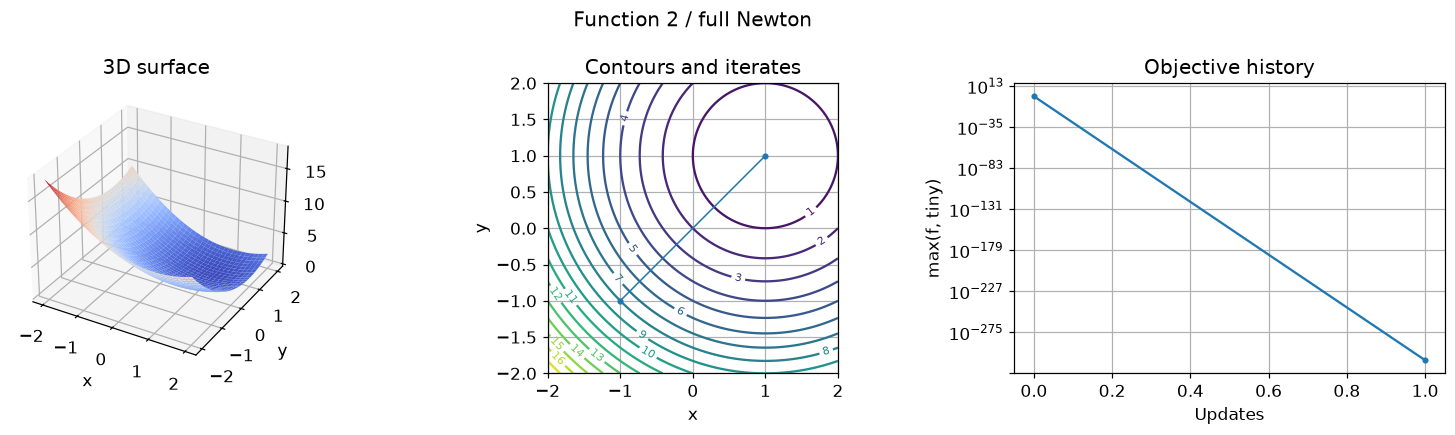

Rosenbrock | updates: 5 | x: [1. 1.] | gradient: 5.334488406560922e-11


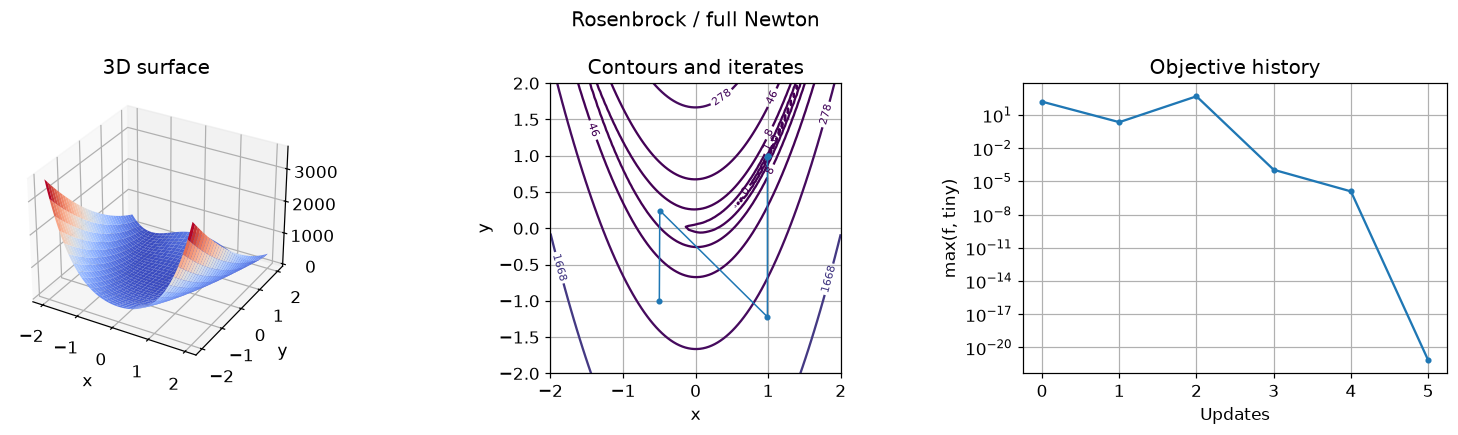

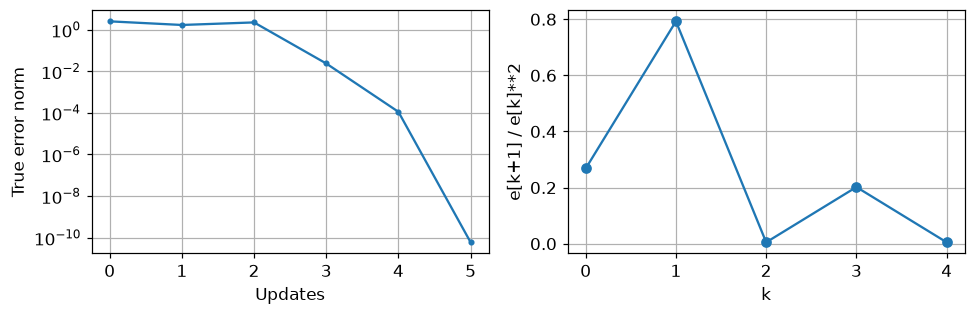

In [13]:
newton_cases = (
    ('Function 1', f1, df1, ddf1, [2., 2./5], [0., 0.]),
    ('Function 2', f2, df2, ddf2, [-1., -1.], [1., 1.]),
    ('Rosenbrock', f3, df3, ddf3, [-.5, -1.], [1., 1.]),
)
newton_results = {}
for name, fun, grad, hess, start, exact in newton_cases:
    result = NewtonMethod(fun, grad, hess, start, maxiter=50, tol=1e-8)
    newton_results = {**newton_results, name: result}
    assert result.converged and np.allclose(result.x, exact, atol=1e-7)
    assert np.all(la.eigvalsh(hess(result.x)) > 0)
    print(name, '| updates:', result.nit, '| x:', result.x, '| gradient:', result.grad_norm)
    plotFunction(fun, steps=result.steps, fhist=result.fhist,
                 levels=np.logspace(-3, 4, 10) if fun is f3 else 20, title=name+' / full Newton')
    if fun is f3:
        plotConvergence(result.steps, exact, 2)
assert newton_results['Function 1'].nit == newton_results['Function 2'].nit == 1

## 6. Verification: derivatives, invariants, and known solutions

In [14]:
# Independent central differences check the analytical derivatives.
for fun, grad, hess in [(f1, df1, ddf1), (f2, df2, ddf2), (f3, df3, ddf3)]:
    point = np.array([.3, -.7])
    basis = np.eye(2)
    eps = 1e-5
    fd_grad = np.array([(fun(point+eps*v)-fun(point-eps*v))/(2*eps) for v in basis])
    fd_hess = np.column_stack([(grad(point+eps*v)-grad(point-eps*v))/(2*eps) for v in basis])
    assert np.allclose(grad(point), fd_grad, rtol=1e-6, atol=1e-6)
    assert np.allclose(hess(point), fd_hess, rtol=1e-6, atol=1e-6)
# Exact quadratic line search, orthogonality, and full-Newton one-step property.
x0 = np.array([2., .4])
g0 = df1(x0)
alpha_exact = (g0@g0)/(g0@ddf1(x0)@g0)
x1 = x0-alpha_exact*g0
assert abs(df1(x1)@g0) < 1e-12
assert np.allclose(x0+la.solve(ddf1(x0), -g0), [0., 0.])
# Stopping at an already stationary point must perform zero updates.
assert NewtonMethod(f1, df1, ddf1, [0., 0.]).nit == 0
assert steepestDescent(f2, df2, [1., 1.]).nit == 0
# Error cases must be explicit rather than silently report an optimum.
for action in [lambda: golden_section(f, 1., -1.),
               lambda: newton_1d(lambda x: 1., lambda x: 0., 0.)]:
    try:
        action()
    except ValueError:
        pass
    else:
        raise AssertionError('Invalid case was not rejected.')
print('Derivative checks, bracket contraction, orthogonality, known optima, and solver guards passed.')
for solver in [lambda: NewtonMethod(lambda x: np.nan, lambda x: np.zeros(2), ddf1, [0., 0.]),
               lambda: steepestDescent(lambda x: np.inf, lambda x: np.zeros(2), [0., 0.])]:
    try:
        solver()
    except FloatingPointError:
        pass
    else:
        raise AssertionError('Nonfinite initial objective was accepted.')

Derivative checks, bracket contraction, orthogonality, known optima, and solver guards passed.


## 7. Compare both methods on a trigonometric objective

<details>
<summary>Example: Trigonometric objective: Newton and fixed-alpha descent</summary>

Let $k=\sqrt2/2$ and
$$f(x,y)=3+\frac{x^2+y^2}{8}-\sin x\cos(ky).$$
At $\mathbf x_0=(\pi/3,\pi/(2\sqrt2))^T$, compute the gradient, Hessian, first Newton point, and first steepest descent point with $\alpha=1.581$.

<details>
<summary>Solution</summary>

The chain rule supplies one factor $k$ for each derivative with respect to $y$:
$$\mathbf g=\begin{bmatrix}x/4-\cos x\cos(ky)\\y/4+k\sin x\sin(ky)\end{bmatrix},$$
$$H=\begin{bmatrix}1/4+\sin x\cos(ky)&k\cos x\sin(ky)\\k\cos x\sin(ky)&1/4+k^2\sin x\cos(ky)\end{bmatrix}.$$
At the given point,
$$\mathbf g_0\approx\begin{bmatrix}-0.0917540028\\0.7106928855\end{bmatrix},\qquad H_0\approx\begin{bmatrix}0.8623724357&0.25\\0.25&0.5561862178\end{bmatrix}.$$
Solving $H_0\mathbf s=-\mathbf g_0$ and adding $\mathbf s$ yields
$$\boxed{\mathbf x_1^{\rm Newton}\approx(1.5954684380,-0.4135180546)^T}.$$
Using the given step length instead yields
$$\boxed{\mathbf x_1^{\rm SD}=\mathbf x_0-1.581\mathbf g_0\approx(1.1922606296,-0.0128847175)^T}.$$
The supplied $\alpha$ belongs to the steepest descent update; it is not automatically a multiplier for the full Newton step.

</details>
</details>

<details>
<summary>Example: Compare two ND methods and plot errors</summary>

For the trigonometric objective above, start both methods at the same $\mathbf r_{\rm init}$. Stop when $\|\nabla f\|_2<\mathrm{stop}$ and report final estimates and update counts. Plot $\log\|\mathbf r_j-\widehat{\mathbf r}\|_2$ using each method's final estimate as its own reference. Include the initial point and omit the final point. Explain this indexing.

<details>
<summary>Solution</summary>

A path with $N$ updates has $N+1$ points: $\mathbf r_0,\ldots,\mathbf r_N$. The reference estimate is $\widehat{\mathbf r}=\mathbf r_N$, so its own final error is exactly zero and $\log0$ is undefined. Plot indices $j=0,\ldots,N-1$, giving exactly $N$ data points. Initialize the two solvers independently, choose $\mathbf s=-\nabla f$ and a scalar line search for steepest descent, and solve $H\mathbf s=-\nabla f$ for Newton.

This plotted “error” is relative to the computed final iterate; it is not a known true solution error. Check Hessian positivity at the final stationary point to support a strict local minimum. The strict stopping condition $<\mathrm{stop}$ corresponds to continuing while the norm is $\ge\mathrm{stop}$, unlike the non-strict tolerance in the earlier generic helpers.

</details>
</details>

Verified trigonometric first steps.
Newton | updates: 4 | point: [ 1.25235323e+00 -7.55515747e-11] | gradient: 9.613651827461154e-11
Steepest descent | updates: 9 | point: [ 1.25235323e+00 -1.00613874e-10] | gradient: 2.525449134085275e-10


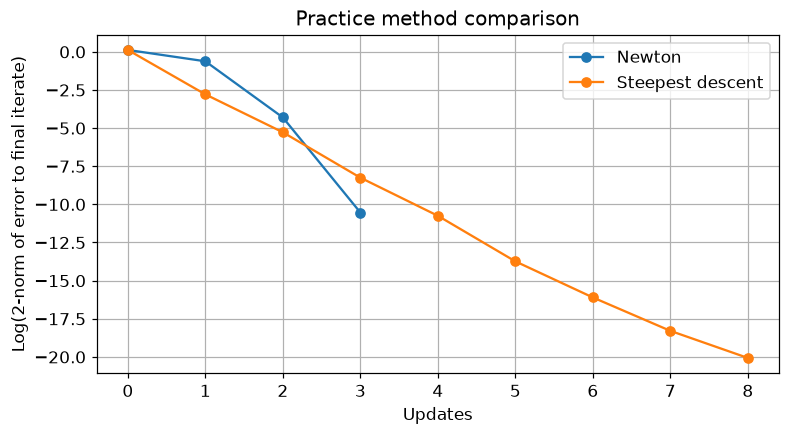

In [15]:
practice_k = 2**-.5

def practice_f(r):
    x, y = r
    return 3+(x*x+y*y)/8-np.sin(x)*np.cos(practice_k*y)

def practice_grad(r):
    x, y = r
    return np.array([x/4-np.cos(x)*np.cos(practice_k*y),
                     y/4+practice_k*np.sin(x)*np.sin(practice_k*y)])

def practice_hess(r):
    x, y = r
    ss = np.sin(x)*np.cos(practice_k*y)
    cc = practice_k*np.cos(x)*np.sin(practice_k*y)
    return np.array([[.25+ss, cc], [cc, .25+practice_k**2*ss]])

r_init = np.array([np.pi/3, np.pi/(2*np.sqrt(2))])
g = practice_grad(r_init)
H = practice_hess(r_init)
assert np.allclose(r_init+la.solve(H, -g), [1.5954684380066548, -.41351805460184])
assert np.allclose(r_init-1.581*g, [1.1922606296141083, -.01288471747878095])
print('Verified trigonometric first steps.')
# Use a slightly stricter helper tolerance to ensure the exercise's strict target.
stop = 1e-8
practice_newton = NewtonMethod(practice_f, practice_grad, practice_hess, r_init, tol=stop/10)
practice_sd = steepestDescent(practice_f, practice_grad, r_init, tol=stop/10)
fig, ax = plt.subplots()
for label, result in [('Newton', practice_newton), ('Steepest descent', practice_sd)]:
    assert result.grad_norm < stop
    assert np.all(la.eigvalsh(practice_hess(result.x)) > 0)
    path = np.asarray(result.steps)
    error = la.norm(path[:-1]-result.x, axis=1)
    assert len(error) == result.nit and np.all(error > 0)
    ax.plot(np.arange(result.nit), np.log(error), 'o-', label=label)
    print(label, '| updates:', result.nit, '| point:', result.x, '| gradient:', result.grad_norm)
ax.set(xlabel='Updates', ylabel='Log(2-norm of error to final iterate)', title='Practice method comparison')
ax.legend(); plt.show()

# IX Method comparison

## 1. What to remember

| Method | Update or invariant | Typical rate under appropriate assumptions | Cost and limitation |
|---|---|---|---|
| Golden Section Search | Retain a unimodal minimum bracket | Width linear, factor $\tau$ | No derivatives; two initial values, one new value per reduction |
| Newton 1D | $x_{k+1}=x_k-f'/f''$ | Locally quadratic near a nondegenerate stationary point | First and second derivatives; can find the wrong type of stationary point |
| Steepest descent ND | $\mathbf s=-\nabla f$, then choose $\alpha$ | Generally linear for well-conditioned strongly convex quadratics | Gradient plus line-search objective calls; slow in narrow valleys |
| Newton ND | Solve $H\mathbf s=-\nabla f$, then $\mathbf x+\mathbf s$ | Locally quadratic near a nondegenerate solution | Hessian plus dense $O(n^3)$ solve; full steps need not decrease the objective |

First distinguish **model**, **stationarity**, **classification**, and **algorithm**. A computed stationary point is a candidate; a positive definite Hessian certifies a strict local minimum, while a global conclusion needs additional reasoning such as convexity or direct comparison.